# Notebook 2: Statistical Testing, Trader Segmentation, Signal Discovery & Report Visuals

**Project:** Traders Behavior Analysis (`Traders-Behavior-Analysis`)  
**Scope:** Phases 5–6 of [`docs/PLAN.md`](docs/PLAN.md) — Hypothesis Testing, Trader Archetype Clustering, Regime-Transition & Strategy Signal Analysis, and Final Report Compilation (`ds_report.pdf`).  
**Prerequisites:** Run `notebook_1.ipynb` first so processed datasets exist in `csv_files/`.

---

## 0. Configuration, Reproducibility & Artifact Helpers

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "csv_files").exists() and (PROJECT_ROOT.parent / "csv_files").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CSV_DIR = PROJECT_ROOT / "csv_files"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CSV_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "figure.figsize": (12, 6),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
})


def save_fig(fig: plt.Figure, filename: str, close: bool = False) -> Path:
    """Save a matplotlib figure cleanly to outputs/ at 300 DPI."""
    out_path = OUTPUT_DIR / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"[Saved Image] {out_path.relative_to(PROJECT_ROOT)}")
    if close:
        plt.close(fig)
    return out_path


def save_table_image(
    df: pd.DataFrame,
    filename: str,
    title: str = "",
    max_rows: int = 25,
    col_width: float = 2.2,
    row_height: float = 0.45,
) -> Path:
    """Render a pandas DataFrame summary table as a crisp PNG image in outputs/."""
    view = df.head(max_rows).copy()
    n_rows, n_cols = view.shape
    fig_w = max(8, n_cols * col_width)
    fig_h = max(2.2, (n_rows + 1.8) * row_height)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=13, fontweight="bold", pad=12, loc="left")

    table = ax.table(
        cellText=view.astype(str).values,
        colLabels=[str(c) for c in view.columns],
        cellLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1.0, 1.4)

    for (r, c), cell in table.get_celld().items():
        if r == 0:
            cell.set_facecolor("#1f3b5c")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor("#f7f9fc" if r % 2 == 0 else "white")
        cell.set_edgecolor("#d0d7de")

    return save_fig(fig, filename, close=True)


def export_csv(df: pd.DataFrame, filename: str, index: bool = False) -> Path:
    """Export a DataFrame to csv_files/ with row/column logging."""
    out_path = CSV_DIR / filename
    df.to_csv(out_path, index=index)
    print(f"[Saved CSV] {out_path.relative_to(PROJECT_ROOT)} | shape={df.shape}")
    return out_path


print(f"Project Root: {PROJECT_ROOT}")

Project Root: c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis


---
## 1. Load Processed Artifacts from Notebook 1

Expected inputs in `csv_files/`:
- `02_merged_trader_sentiment.csv`
- `03_features_daily_regime.csv`
- `04_features_trader_profiles.csv`

In [2]:
expected_files = [
    '01_clean_sentiment.csv',
    '02_merged_trader_sentiment.csv',
    '03_features_daily_regime.csv',
    '04_features_trader_profiles.csv',
]
for fname in expected_files:
    fpath = CSV_DIR / fname
    status = 'FOUND' if fpath.exists() else 'MISSING (run notebook_1.ipynb first)'
    print(f'{fname}: {status}')
    assert fpath.exists(), f'Required input missing: {fpath}'

# Load persisted Phase 1-4 artifacts
df_sent_clean = pd.read_csv(CSV_DIR / '01_clean_sentiment.csv')
df_trades = pd.read_csv(CSV_DIR / '02_merged_trader_sentiment.csv', low_memory=False)
df_daily = pd.read_csv(CSV_DIR / '03_features_daily_regime.csv')
df_traders = pd.read_csv(CSV_DIR / '04_features_trader_profiles.csv')

# Schema & row-count assertions matching verified Phase 2-4 outputs
assert len(df_trades) == 211224, f'Expected 211224 trades, got {len(df_trades)}'
assert len(df_daily) == 476, f'Expected 476 active daily rows, got {len(df_daily)}'
assert len(df_traders) == 32, f'Expected 32 trader profiles, got {len(df_traders)}'
assert df_trades['sentiment_value'].isna().sum() == 0, 'Null sentiment_value in merged trades'

REGIME_ORDER = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
COARSE_ORDER = ['Fear', 'Neutral', 'Greed']
REGIME_COLORS = {
    'Extreme Fear': '#b91c1c',
    'Fear': '#ea580c',
    'Neutral': '#64748b',
    'Greed': '#16a34a',
    'Extreme Greed': '#15803d',
}
COARSE_COLORS = {'Fear': '#dc2626', 'Neutral': '#64748b', 'Greed': '#16a34a'}

# Parse dates & enforce ordered regime categoricals
df_sent_clean['date_dt'] = pd.to_datetime(df_sent_clean['sentiment_date_str'])
df_trades['trade_date_dt'] = pd.to_datetime(df_trades['trade_date_utc'])
df_trades['timestamp_utc_dt'] = pd.to_datetime(df_trades['timestamp_utc'], utc=True)
df_trades['sentiment_class'] = pd.Categorical(df_trades['sentiment_class'], categories=REGIME_ORDER, ordered=True)
df_trades['regime_coarse'] = pd.Categorical(df_trades['regime_coarse'], categories=COARSE_ORDER, ordered=True)

df_daily['trade_date_dt'] = pd.to_datetime(df_daily['trade_date_utc'])
df_daily = df_daily.sort_values('trade_date_dt').reset_index(drop=True)
df_daily['sentiment_class'] = pd.Categorical(df_daily['sentiment_class'], categories=REGIME_ORDER, ordered=True)
df_daily['regime_coarse'] = pd.Categorical(df_daily['regime_coarse'], categories=COARSE_ORDER, ordered=True)

# Recompute deterministic Phase 4 trade-level flags on df_trades for Phase 5 tests
df_trades['net_pnl_after_fee'] = df_trades['closed_pnl'] - df_trades['fee']
df_trades['is_win'] = df_trades['is_closing_trade'] & (df_trades['closed_pnl'] > 0)
df_trades['is_loss'] = df_trades['is_closing_trade'] & (df_trades['closed_pnl'] < 0)
df_trades['return_on_notional_pct'] = np.where(
    df_trades['size_usd'] > 0,
    100.0 * df_trades['closed_pnl'] / df_trades['size_usd'],
    np.nan,
)
df_trades['is_perp_open_long'] = df_trades['direction'].eq('Open Long')
df_trades['is_perp_open_short'] = df_trades['direction'].eq('Open Short')
df_trades['is_perp_open'] = df_trades['is_perp_open_long'] | df_trades['is_perp_open_short']
df_trades['is_contrarian_open'] = (
    (df_trades['regime_coarse'].eq('Fear') & df_trades['is_perp_open_long'])
    | (df_trades['regime_coarse'].eq('Greed') & df_trades['is_perp_open_short'])
)
df_trades['is_momentum_open'] = (
    (df_trades['regime_coarse'].eq('Fear') & df_trades['is_perp_open_short'])
    | (df_trades['regime_coarse'].eq('Greed') & df_trades['is_perp_open_long'])
)

print()
print(f'Loaded df_trades : {df_trades.shape} | Closing trades: {int(df_trades["is_closing_trade"].sum()):,} | Perp opens: {int(df_trades["is_perp_open"].sum()):,}')
print(f'Loaded df_daily  : {df_daily.shape} | Date range: {df_daily["trade_date_utc"].min()} -> {df_daily["trade_date_utc"].max()}')
print(f'Loaded df_traders: {df_traders.shape} | Min trades/acct: {int(df_traders["total_trades"].min()):,}')
print('5-Regime daily counts:', df_daily['sentiment_class'].value_counts().reindex(REGIME_ORDER).to_dict())
print('Coarse daily counts  :', df_daily['regime_coarse'].value_counts().reindex(COARSE_ORDER).to_dict())

01_clean_sentiment.csv: FOUND
02_merged_trader_sentiment.csv: FOUND
03_features_daily_regime.csv: FOUND
04_features_trader_profiles.csv: FOUND

Loaded df_trades : (211224, 50) | Closing trades: 104,408 | Perp opens: 89,636
Loaded df_daily  : (476, 44) | Date range: 2023-04-30 -> 2025-05-01
Loaded df_traders: (32, 63) | Min trades/acct: 332
5-Regime daily counts: {'Extreme Fear': 14, 'Fear': 89, 'Neutral': 64, 'Greed': 197, 'Extreme Greed': 112}
Coarse daily counts  : {'Fear': 103, 'Neutral': 64, 'Greed': 309}


---
## 2. Phase 5A: Hypothesis Testing Across Market Regimes

- Non-parametric tests (Mann-Whitney U, Kruskal-Wallis), contingency tests (Chi-Square), effect sizes, FDR correction, and bootstrap 95% confidence intervals.
- Export `csv_files/05_stats_regime_tests.csv` and save `outputs/07_stats_*.png`.

[Saved CSV] csv_files\05_stats_regime_tests.csv | shape=(19, 22)


,level,metric,summary_stat,fear_summary,greed_summary,p_5reg_fdr,p_fg_fdr,effect_fg,effect_fg_name,sig_fg_fdr05
0,Daily,trade_count,Median,269.000000,61.000000,2.368016e-06,9.568367e-04,0.227134,Cliffs_Delta,True
1,Daily,active_accounts,Median,8.000000,2.000000,5.960209e-11,4.848078e-09,0.384642,Cliffs_Delta,True
2,Daily,total_volume_usd,Median,711405.400000,270989.970000,1.011866e-04,4.605085e-03,0.195840,Cliffs_Delta,True
3,Daily,median_size_usd,Median,653.070000,867.360000,6.787868e-03,3.513866e-02,-0.144783,Cliffs_Delta,True
4,Daily,net_pnl_usd,Median,4178.427732,1127.436985,1.168925e-05,2.255521e-02,0.157445,Cliffs_Delta,True
5,Daily,net_pnl_after_fees,Median,4057.187462,1070.269622,1.088737e-05,2.255521e-02,0.158042,Cliffs_Delta,True
6,Daily,win_rate_pct,Median,94.083690,96.066253,4.170206e-02,4.316618e-01,-0.056598,Cliffs_Delta,False
7,Daily,taker_pct,Median,76.315789,85.135135,1.011866e-04,6.187946e-01,-0.032237,Cliffs_Delta,False
8,Daily,spot_pct,Median,8.358209,0.000000,1.103453e-15,3.914015e-17,0.511767,Cliffs_Delta,True
9,Daily,open_long_share_pct,Median,67.942584,51.146076,2.337120e-01,8.453549e-02,0.122861,Cliffs_Delta,False


[Saved CSV] csv_files\05_stats_bootstrap_ci.csv | shape=(11, 13)


,level,label,obs_a,obs_b,diff_fear_minus_greed,ci95_low,ci95_high,excludes_zero
0,Daily,Daily Trades (Median),269.000000,61.000000,208.000000,-3.000000,636.050000,False
1,Daily,"Daily Volume (USD M, Median)",0.711405,0.270990,0.440415,0.021845,2.476563,True
2,Daily,"Daily Median Size (USD, Median)",653.070000,867.360000,-214.290000,-446.277250,7.257250,False
3,Daily,"Daily Net PnL (USD K, Mean)",38.255826,16.357877,21.897949,3.897991,41.508223,True
4,Daily,"Daily Win Rate (pp, Mean)",84.062556,83.568211,0.494345,-5.558108,6.351979,False
5,Daily,"Daily Taker Share (pp, Mean)",74.041717,74.507206,-0.465490,-6.696010,5.172776,False
6,Daily,"Daily Open-Long Share (pp, Mean)",60.684039,51.750719,8.933321,0.365312,17.095432,True
7,Trade,"Trade Size (USD, Median)",730.830000,550.020000,180.810000,163.124125,198.360125,True
8,Trade,"Closing PnL/Trade (USD, Mean)",95.672075,111.553135,-15.881060,-33.040815,3.128830,False
9,Trade,Closing Win Rate (pp),84.438887,83.313103,1.125784,0.645927,1.612466,True


[Saved Image] outputs\07_stats_summary_table.png
[Saved Image] outputs\07_stats_hypothesis_tests.png
[Saved Image] outputs\07_stats_bootstrap_ci.png
Phase 5A complete: exported 05_stats_regime_tests.csv, 05_stats_bootstrap_ci.csv, and 07_stats_*.png


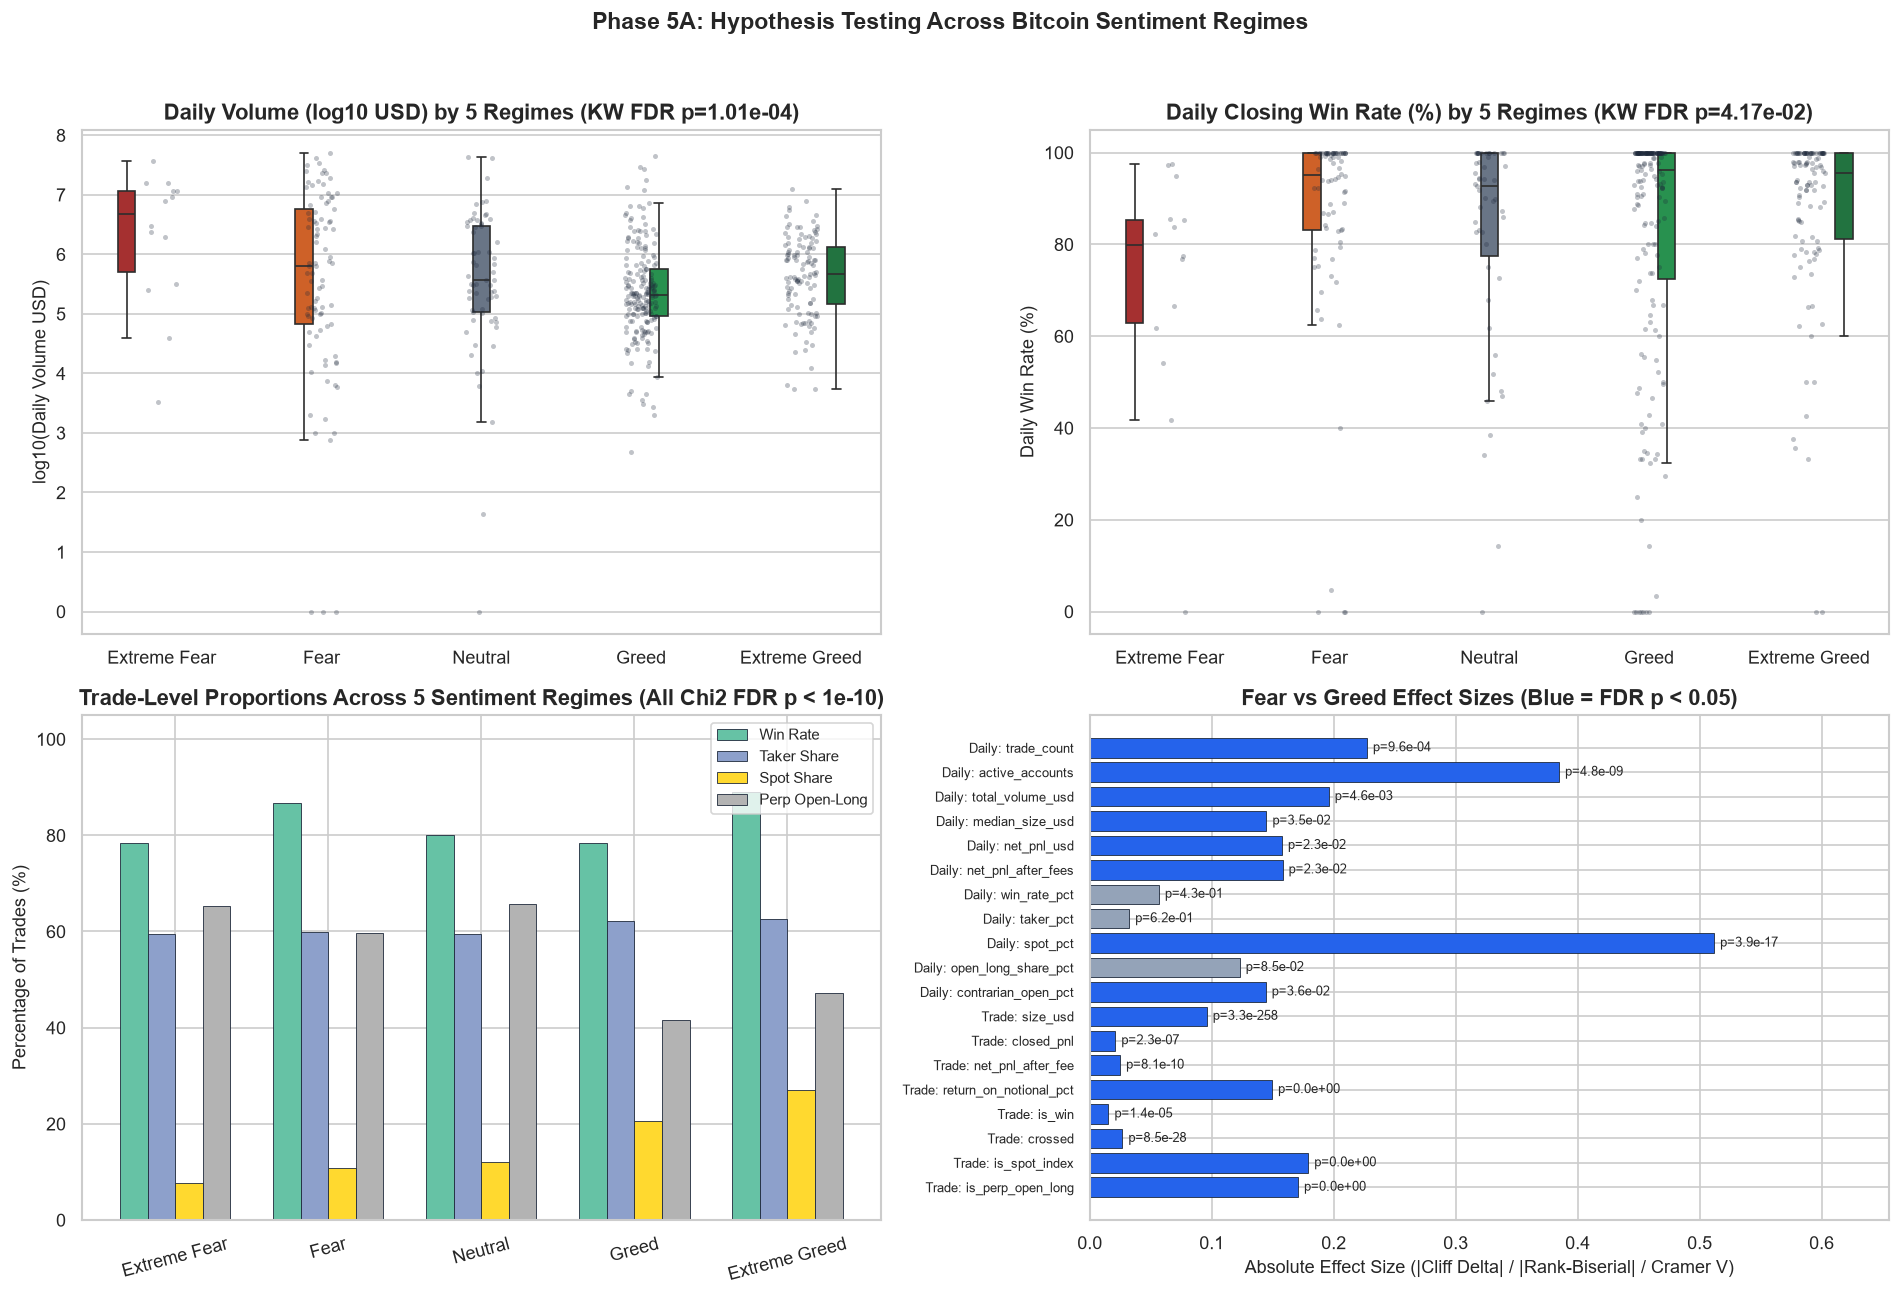

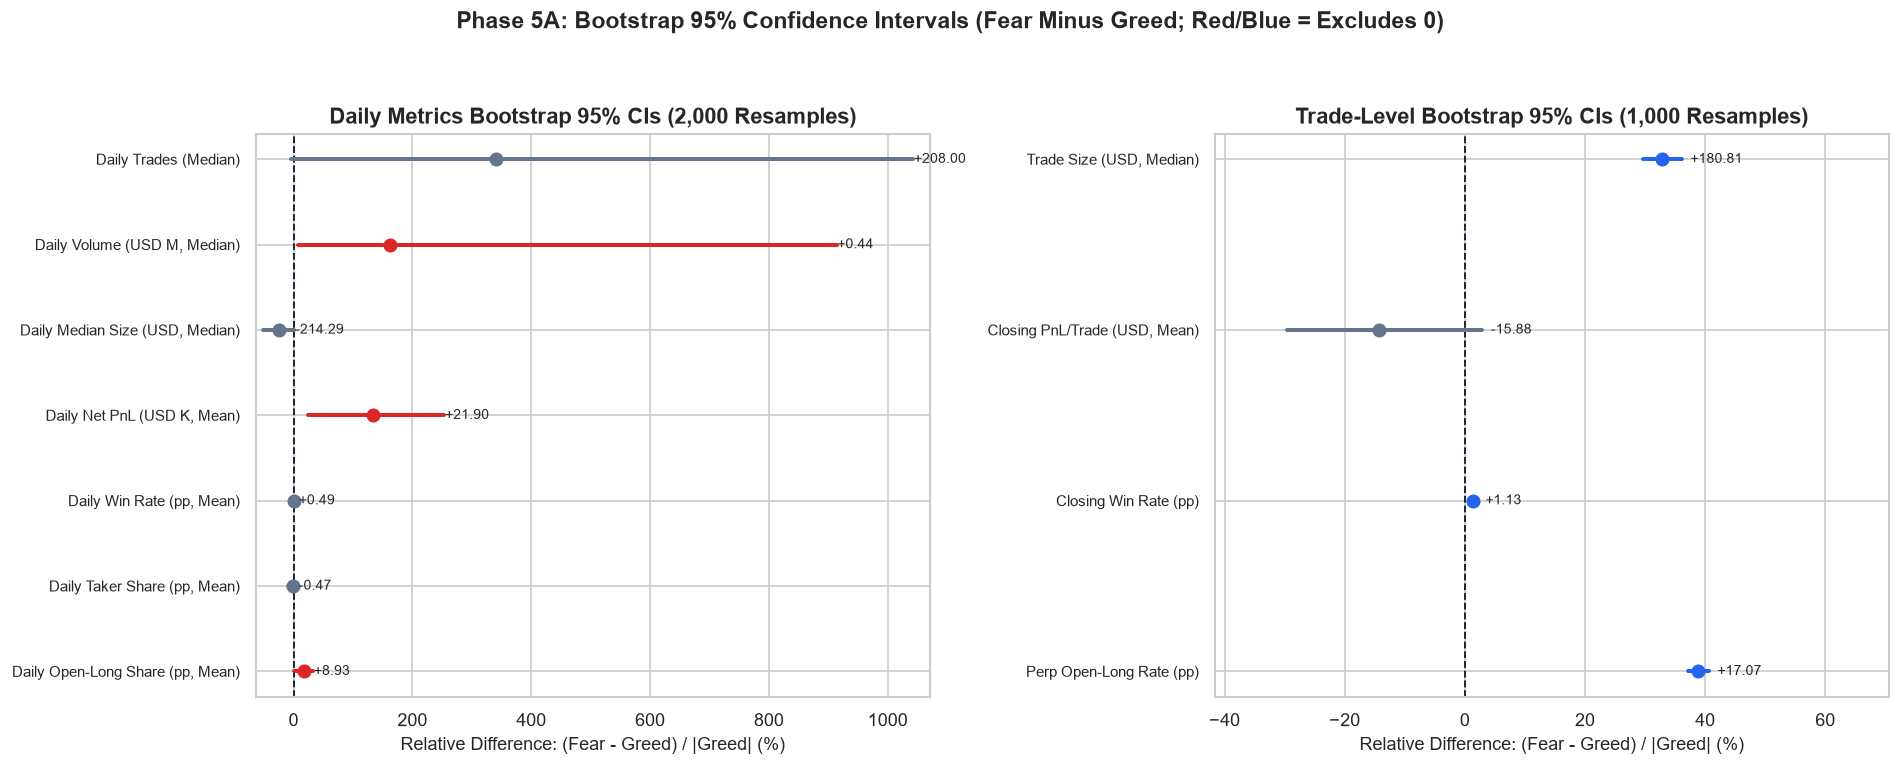

In [3]:
from statsmodels.stats.multitest import multipletests

def rank_biserial_and_cliffs(x_fear, y_greed, compute_exact_cliffs=False):
    """Compute Mann-Whitney U, two-sided p-value, and Fear-vs-Greed rank-biserial (positive => Fear > Greed)."""
    x = np.asarray(x_fear, dtype=float)
    y = np.asarray(y_greed, dtype=float)
    x = x[np.isfinite(x)]
    y = y[np.isfinite(y)]
    n1, n2 = len(x), len(y)
    u_stat, p_val = stats.mannwhitneyu(x, y, alternative='two-sided')
    # u_stat corresponds to first sample x_fear; r_rb in [-1, 1], positive means x_fear tends larger
    rank_biserial = (2.0 * u_stat) / (n1 * n2) - 1.0
    cliffs = rank_biserial
    if compute_exact_cliffs and (n1 * n2) <= 200000:
        diff_mat = x[:, None] - y[None, :]
        cliffs = float(np.mean(np.sign(diff_mat)))
    return float(u_stat), float(p_val), float(rank_biserial), float(cliffs), n1, n2

def cramers_v_from_table(ct):
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    n = ct.to_numpy().sum()
    min_dim = min(ct.shape[0] - 1, ct.shape[1] - 1)
    v = np.sqrt(chi2 / (n * min_dim)) if (n > 0 and min_dim > 0) else 0.0
    return float(chi2), float(p_val), int(dof), float(v)

test_rows = []

# --- A. Daily-level continuous hypothesis tests (N = 476 active days) ---
daily_metrics = [
    ('trade_count', 'Daily Trade Count'),
    ('active_accounts', 'Daily Active Accounts'),
    ('total_volume_usd', 'Daily Volume (USD)'),
    ('median_size_usd', 'Daily Median Size (USD)'),
    ('net_pnl_usd', 'Daily Net PnL (USD)'),
    ('net_pnl_after_fees', 'Daily Net PnL After Fees (USD)'),
    ('win_rate_pct', 'Daily Closing Win Rate (%)'),
    ('taker_pct', 'Daily Taker Share (%)'),
    ('spot_pct', 'Daily Spot Share (%)'),
    ('open_long_share_pct', 'Daily Perp Open Long Share (%)'),
    ('contrarian_open_pct', 'Daily Contrarian Open Share (%)'),
]

df_daily_fear = df_daily[df_daily['regime_coarse'] == 'Fear']
df_daily_greed = df_daily[df_daily['regime_coarse'] == 'Greed']

for col, label in daily_metrics:
    groups_5 = [g[col].dropna().values for _, g in df_daily.groupby('sentiment_class', observed=True)]
    valid_5 = [g for g in groups_5 if len(g) > 0]
    kw_h, kw_p = stats.kruskal(*valid_5)
    n_tot = sum(len(g) for g in valid_5)
    k_grp = len(valid_5)
    eps_sq = max(0.0, (kw_h - k_grp + 1.0) / (n_tot - k_grp)) if n_tot > k_grp else 0.0

    u_stat, mw_p, r_rb, cliffs, n_f, n_g = rank_biserial_and_cliffs(
        df_daily_fear[col], df_daily_greed[col], compute_exact_cliffs=True
    )
    test_rows.append({
        'level': 'Daily',
        'test_family': 'Continuous (KW + MW-U)',
        'metric': col,
        'label': label,
        'n_total': n_tot,
        'n_fear': n_f,
        'n_greed': n_g,
        'fear_summary': float(df_daily_fear[col].median()),
        'greed_summary': float(df_daily_greed[col].median()),
        'summary_stat': 'Median',
        'kw_or_chi2_5reg': float(kw_h),
        'p_5reg': float(kw_p),
        'effect_5reg': float(eps_sq),
        'mw_u_or_chi2_fg': float(u_stat),
        'p_fg': float(mw_p),
        'effect_fg': float(cliffs),
        'effect_fg_name': 'Cliffs_Delta',
    })

# --- B. Trade-level continuous hypothesis tests ---
df_closing = df_trades[df_trades['is_closing_trade']].copy()
trade_cont_specs = [
    (df_trades, 'size_usd', 'Trade Notional Size (USD, All)'),
    (df_closing, 'closed_pnl', 'Trade Closed PnL (USD, Closing)'),
    (df_closing, 'net_pnl_after_fee', 'Trade Net PnL After Fee (USD, Closing)'),
    (df_closing, 'return_on_notional_pct', 'Return on Notional (%, Closing)'),
]

for sub_df, col, label in trade_cont_specs:
    groups_5 = [g[col].dropna().values for _, g in sub_df.groupby('sentiment_class', observed=True)]
    valid_5 = [g for g in groups_5 if len(g) > 0]
    kw_h, kw_p = stats.kruskal(*valid_5)
    n_tot = sum(len(g) for g in valid_5)
    k_grp = len(valid_5)
    eps_sq = max(0.0, (kw_h - k_grp + 1.0) / (n_tot - k_grp))

    f_vals = sub_df.loc[sub_df['regime_coarse'] == 'Fear', col]
    g_vals = sub_df.loc[sub_df['regime_coarse'] == 'Greed', col]
    u_stat, mw_p, r_rb, _, n_f, n_g = rank_biserial_and_cliffs(f_vals, g_vals, compute_exact_cliffs=False)
    test_rows.append({
        'level': 'Trade',
        'test_family': 'Continuous (KW + MW-U)',
        'metric': col,
        'label': label,
        'n_total': n_tot,
        'n_fear': n_f,
        'n_greed': n_g,
        'fear_summary': float(f_vals.mean()),
        'greed_summary': float(g_vals.mean()),
        'summary_stat': 'Mean',
        'kw_or_chi2_5reg': float(kw_h),
        'p_5reg': float(kw_p),
        'effect_5reg': float(eps_sq),
        'mw_u_or_chi2_fg': float(u_stat),
        'p_fg': float(mw_p),
        'effect_fg': float(r_rb),
        'effect_fg_name': 'Rank_Biserial',
    })

# --- C. Trade-level proportion / contingency tests (Chi-Square + Cramer V) ---
df_perp_opens = df_trades[df_trades['is_perp_open']].copy()
prop_specs = [
    (df_closing, 'is_win', 'Closing Trade Win Rate (%)'),
    (df_trades, 'crossed', 'Taker Execution Rate (%)'),
    (df_trades, 'is_spot_index', 'Spot Trade Share (%)'),
    (df_perp_opens, 'is_perp_open_long', 'Perp Open-Long Share (%)'),
]

for sub_df, col, label in prop_specs:
    ct5 = pd.crosstab(sub_df['sentiment_class'], sub_df[col])
    chi2_5, p_5, _, v_5 = cramers_v_from_table(ct5)

    fg_sub = sub_df[sub_df['regime_coarse'].isin(['Fear', 'Greed'])].copy()
    fg_sub['regime_fg'] = fg_sub['regime_coarse'].astype(str)
    ct_fg = pd.crosstab(fg_sub['regime_fg'], fg_sub[col])
    chi2_fg, p_fg, _, v_fg = cramers_v_from_table(ct_fg)

    rate_f = 100.0 * fg_sub.loc[fg_sub['regime_fg'] == 'Fear', col].mean()
    rate_g = 100.0 * fg_sub.loc[fg_sub['regime_fg'] == 'Greed', col].mean()
    test_rows.append({
        'level': 'Trade',
        'test_family': 'Proportion (Chi-Square)',
        'metric': col,
        'label': label,
        'n_total': int(len(sub_df)),
        'n_fear': int((fg_sub['regime_fg'] == 'Fear').sum()),
        'n_greed': int((fg_sub['regime_fg'] == 'Greed').sum()),
        'fear_summary': float(rate_f),
        'greed_summary': float(rate_g),
        'summary_stat': 'Rate (%)',
        'kw_or_chi2_5reg': float(chi2_5),
        'p_5reg': float(p_5),
        'effect_5reg': float(v_5),
        'mw_u_or_chi2_fg': float(chi2_fg),
        'p_fg': float(p_fg),
        'effect_fg': float(v_fg),
        'effect_fg_name': 'Cramers_V',
    })

df_tests = pd.DataFrame(test_rows)
_, df_tests['p_5reg_fdr'], _, _ = multipletests(df_tests['p_5reg'], method='fdr_bh')
_, df_tests['p_fg_fdr'], _, _ = multipletests(df_tests['p_fg'], method='fdr_bh')
df_tests['sig_5reg_fdr05'] = df_tests['p_5reg_fdr'] < 0.05
df_tests['sig_fg_fdr05'] = df_tests['p_fg_fdr'] < 0.05
df_tests['fear_minus_greed'] = df_tests['fear_summary'] - df_tests['greed_summary']

export_csv(df_tests, '05_stats_regime_tests.csv')
display(df_tests[['level', 'metric', 'summary_stat', 'fear_summary', 'greed_summary', 'p_5reg_fdr', 'p_fg_fdr', 'effect_fg', 'effect_fg_name', 'sig_fg_fdr05']])

# --- D. Bootstrap 95% CIs for Fear minus Greed Differences ---
rng = np.random.default_rng(RANDOM_STATE)

def bootstrap_diff(arr_a, arr_b, stat_fn, n_boot=2000, scale=1.0):
    a = np.asarray(arr_a, dtype=float)
    b = np.asarray(arr_b, dtype=float)
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]
    obs = scale * (stat_fn(a) - stat_fn(b))
    na, nb = len(a), len(b)
    diffs = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        sa = a[rng.integers(0, na, size=na)]
        sb = b[rng.integers(0, nb, size=nb)]
        diffs[i] = scale * (stat_fn(sa) - stat_fn(sb))
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    base = abs(scale * stat_fn(b))
    rel_pct = 100.0 * obs / base if base > 1e-12 else np.nan
    rel_low = 100.0 * ci_low / base if base > 1e-12 else np.nan
    rel_high = 100.0 * ci_high / base if base > 1e-12 else np.nan
    return {
        'obs_a': float(scale * stat_fn(a)),
        'obs_b': float(scale * stat_fn(b)),
        'diff_fear_minus_greed': float(obs),
        'ci95_low': float(ci_low),
        'ci95_high': float(ci_high),
        'rel_diff_pct': float(rel_pct),
        'rel_ci95_low': float(rel_low),
        'rel_ci95_high': float(rel_high),
        'excludes_zero': bool((ci_low > 0) or (ci_high < 0)),
        'n_boot': int(n_boot),
    }

boot_specs = [
    ('Daily', 'trade_count', 'Daily Trades (Median)', df_daily_fear['trade_count'], df_daily_greed['trade_count'], np.median, 2000, 1.0),
    ('Daily', 'total_volume_usd', 'Daily Volume (USD M, Median)', df_daily_fear['total_volume_usd'], df_daily_greed['total_volume_usd'], np.median, 2000, 1e-6),
    ('Daily', 'median_size_usd', 'Daily Median Size (USD, Median)', df_daily_fear['median_size_usd'], df_daily_greed['median_size_usd'], np.median, 2000, 1.0),
    ('Daily', 'net_pnl_usd', 'Daily Net PnL (USD K, Mean)', df_daily_fear['net_pnl_usd'], df_daily_greed['net_pnl_usd'], np.mean, 2000, 1e-3),
    ('Daily', 'win_rate_pct', 'Daily Win Rate (pp, Mean)', df_daily_fear['win_rate_pct'], df_daily_greed['win_rate_pct'], np.mean, 2000, 1.0),
    ('Daily', 'taker_pct', 'Daily Taker Share (pp, Mean)', df_daily_fear['taker_pct'], df_daily_greed['taker_pct'], np.mean, 2000, 1.0),
    ('Daily', 'open_long_share_pct', 'Daily Open-Long Share (pp, Mean)', df_daily_fear['open_long_share_pct'], df_daily_greed['open_long_share_pct'], np.mean, 2000, 1.0),
    ('Trade', 'size_usd', 'Trade Size (USD, Median)', df_trades.loc[df_trades['regime_coarse'] == 'Fear', 'size_usd'], df_trades.loc[df_trades['regime_coarse'] == 'Greed', 'size_usd'], np.median, 1000, 1.0),
    ('Trade', 'closed_pnl', 'Closing PnL/Trade (USD, Mean)', df_closing.loc[df_closing['regime_coarse'] == 'Fear', 'closed_pnl'], df_closing.loc[df_closing['regime_coarse'] == 'Greed', 'closed_pnl'], np.mean, 1000, 1.0),
    ('Trade', 'is_win', 'Closing Win Rate (pp)', df_closing.loc[df_closing['regime_coarse'] == 'Fear', 'is_win'].astype(float), df_closing.loc[df_closing['regime_coarse'] == 'Greed', 'is_win'].astype(float), np.mean, 1000, 100.0),
    ('Trade', 'is_perp_open_long', 'Perp Open-Long Rate (pp)', df_perp_opens.loc[df_perp_opens['regime_coarse'] == 'Fear', 'is_perp_open_long'].astype(float), df_perp_opens.loc[df_perp_opens['regime_coarse'] == 'Greed', 'is_perp_open_long'].astype(float), np.mean, 1000, 100.0),
]

boot_rows = []
for level, metric, label, arr_f, arr_g, fn, nb, sc in boot_specs:
    res = bootstrap_diff(arr_f, arr_g, fn, n_boot=nb, scale=sc)
    res.update({'level': level, 'metric': metric, 'label': label})
    boot_rows.append(res)
df_boot = pd.DataFrame(boot_rows)
export_csv(df_boot, '05_stats_bootstrap_ci.csv')
display(df_boot[['level', 'label', 'obs_a', 'obs_b', 'diff_fear_minus_greed', 'ci95_low', 'ci95_high', 'excludes_zero']])

# --- E. Visual Summary Table (07_stats_summary_table.png) ---
tbl_display = df_tests.copy()
tbl_display['Fear'] = tbl_display['fear_summary'].map(lambda v: f'{v:,.2f}')
tbl_display['Greed'] = tbl_display['greed_summary'].map(lambda v: f'{v:,.2f}')
tbl_display['p_5reg_FDR'] = tbl_display['p_5reg_fdr'].map(lambda p: f'{p:.2e}')
tbl_display['p_FG_FDR'] = tbl_display['p_fg_fdr'].map(lambda p: f'{p:.2e}')
tbl_display['Effect_FG'] = tbl_display.apply(lambda r: f"{r['effect_fg']:+.3f} ({r['effect_fg_name'][:6]})", axis=1)
tbl_display['Sig_FG'] = np.where(tbl_display['sig_fg_fdr05'], 'YES (FDR<0.05)', 'No')
save_table_image(
    tbl_display[['level', 'label', 'summary_stat', 'Fear', 'Greed', 'p_5reg_FDR', 'p_FG_FDR', 'Effect_FG', 'Sig_FG']],
    '07_stats_summary_table.png',
    title='Phase 5A: Hypothesis Tests Across Market Sentiment Regimes (FDR Corrected)',
    max_rows=25,
    col_width=2.05,
    row_height=0.42,
)

# --- F. Multi-panel Hypothesis Test Visual (07_stats_hypothesis_tests.png) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
palette_5 = [REGIME_COLORS[r] for r in REGIME_ORDER]

# Panel 1: Daily Volume (log10) by 5 regimes
df_plot = df_daily.copy()
df_plot['log10_vol'] = np.log10(df_plot['total_volume_usd'].clip(lower=1.0))
sns.boxplot(data=df_plot, x='sentiment_class', y='log10_vol', hue='sentiment_class', order=REGIME_ORDER, palette=palette_5, legend=False, ax=axes[0, 0], width=0.55, showfliers=False)
sns.stripplot(data=df_plot, x='sentiment_class', y='log10_vol', order=REGIME_ORDER, color='#1e293b', alpha=0.28, size=3, ax=axes[0, 0])
kw_vol_p = df_tests.loc[(df_tests['level'] == 'Daily') & (df_tests['metric'] == 'total_volume_usd'), 'p_5reg_fdr'].iloc[0]
axes[0, 0].set_title(f'Daily Volume (log10 USD) by 5 Regimes (KW FDR p={kw_vol_p:.2e})', fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('log10(Daily Volume USD)')

# Panel 2: Daily Win Rate (%) by 5 regimes
sns.boxplot(data=df_plot, x='sentiment_class', y='win_rate_pct', hue='sentiment_class', order=REGIME_ORDER, palette=palette_5, legend=False, ax=axes[0, 1], width=0.55, showfliers=False)
sns.stripplot(data=df_plot, x='sentiment_class', y='win_rate_pct', order=REGIME_ORDER, color='#1e293b', alpha=0.28, size=3, ax=axes[0, 1])
kw_wr_p = df_tests.loc[(df_tests['level'] == 'Daily') & (df_tests['metric'] == 'win_rate_pct'), 'p_5reg_fdr'].iloc[0]
axes[0, 1].set_title(f'Daily Closing Win Rate (%) by 5 Regimes (KW FDR p={kw_wr_p:.2e})', fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Daily Win Rate (%)')

# Panel 3: Trade-level rates (Win Rate, Taker Rate, Spot Rate, Open-Long Rate) across 5 regimes
rate_rows = []
for reg in REGIME_ORDER:
    sub_all = df_trades[df_trades['sentiment_class'] == reg]
    sub_cls = df_closing[df_closing['sentiment_class'] == reg]
    sub_op = df_perp_opens[df_perp_opens['sentiment_class'] == reg]
    rate_rows.append({
        'regime': reg,
        'Win Rate': 100.0 * sub_cls['is_win'].mean(),
        'Taker Share': 100.0 * sub_all['crossed'].mean(),
        'Spot Share': 100.0 * sub_all['is_spot_index'].mean(),
        'Perp Open-Long': 100.0 * sub_op['is_perp_open_long'].mean(),
    })
df_rates = pd.DataFrame(rate_rows).set_index('regime')
df_rates.plot(kind='bar', ax=axes[1, 0], width=0.72, colormap='Set2', edgecolor='#1e293b', linewidth=0.5)
axes[1, 0].set_title('Trade-Level Proportions Across 5 Sentiment Regimes (All Chi2 FDR p < 1e-10)', fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Percentage of Trades (%)')
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].legend(loc='upper right', fontsize=9)
axes[1, 0].set_ylim(0, 105)

# Panel 4: Effect size vs -log10(FDR p-value) summary across Fear vs Greed tests
plot_eff = df_tests.copy()
plot_eff['neg_log10_p'] = -np.log10(plot_eff['p_fg_fdr'].clip(lower=1e-50))
plot_eff['abs_effect'] = plot_eff['effect_fg'].abs()
y_pos = np.arange(len(plot_eff))
colors_sig = ['#2563eb' if s else '#94a3b8' for s in plot_eff['sig_fg_fdr05']]
axes[1, 1].barh(y_pos, plot_eff['abs_effect'], color=colors_sig, edgecolor='#1e293b', linewidth=0.5)
axes[1, 1].set_yticks(y_pos)
axes[1, 1].set_yticklabels([f"{r['level']}: {r['metric']}" for _, r in plot_eff.iterrows()], fontsize=8)
axes[1, 1].invert_yaxis()
axes[1, 1].set_xlabel('Absolute Effect Size (|Cliff Delta| / |Rank-Biserial| / Cramer V)')
axes[1, 1].set_title('Fear vs Greed Effect Sizes (Blue = FDR p < 0.05)', fontweight='bold')
for idx, (_, r) in enumerate(plot_eff.iterrows()):
    axes[1, 1].text(r['abs_effect'] + 0.005, idx, f"p={r['p_fg_fdr']:.1e}", va='center', fontsize=7.5)
axes[1, 1].set_xlim(0, max(0.35, plot_eff['abs_effect'].max() * 1.28))

fig.suptitle('Phase 5A: Hypothesis Testing Across Bitcoin Sentiment Regimes', fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_fig(fig, '07_stats_hypothesis_tests.png')

# --- G. Bootstrap 95% CI Forest Plot (07_stats_bootstrap_ci.png) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
boot_daily = df_boot[df_boot['level'] == 'Daily'].copy()
boot_trade = df_boot[df_boot['level'] == 'Trade'].copy()

y_d = np.arange(len(boot_daily))
col_d = ['#dc2626' if ex else '#64748b' for ex in boot_daily['excludes_zero']]
axes[0].axvline(0.0, color='#0f172a', linestyle='--', linewidth=1.1)
for i, (_, r) in enumerate(boot_daily.iterrows()):
    c = col_d[i]
    axes[0].plot([r['rel_ci95_low'], r['rel_ci95_high']], [i, i], color=c, linewidth=2.4)
    axes[0].scatter([r['rel_diff_pct']], [i], color=c, s=55, zorder=3)
    axes[0].text(r['rel_ci95_high'] + 1.5, i, f"{r['diff_fear_minus_greed']:+.2f}", va='center', fontsize=8.5)
axes[0].set_yticks(y_d)
axes[0].set_yticklabels(boot_daily['label'], fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel('Relative Difference: (Fear - Greed) / |Greed| (%)')
axes[0].set_title('Daily Metrics Bootstrap 95% CIs (2,000 Resamples)', fontweight='bold')
axes[0].set_xlim(boot_daily['rel_ci95_low'].min() - 12, boot_daily['rel_ci95_high'].max() + 28)

y_t = np.arange(len(boot_trade))
col_t = ['#2563eb' if ex else '#64748b' for ex in boot_trade['excludes_zero']]
axes[1].axvline(0.0, color='#0f172a', linestyle='--', linewidth=1.1)
for i, (_, r) in enumerate(boot_trade.iterrows()):
    c = col_t[i]
    axes[1].plot([r['rel_ci95_low'], r['rel_ci95_high']], [i, i], color=c, linewidth=2.4)
    axes[1].scatter([r['rel_diff_pct']], [i], color=c, s=55, zorder=3)
    axes[1].text(r['rel_ci95_high'] + 1.5, i, f"{r['diff_fear_minus_greed']:+.2f}", va='center', fontsize=8.5)
axes[1].set_yticks(y_t)
axes[1].set_yticklabels(boot_trade['label'], fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlabel('Relative Difference: (Fear - Greed) / |Greed| (%)')
axes[1].set_title('Trade-Level Bootstrap 95% CIs (1,000 Resamples)', fontweight='bold')
axes[1].set_xlim(boot_trade['rel_ci95_low'].min() - 12, boot_trade['rel_ci95_high'].max() + 30)

fig.suptitle('Phase 5A: Bootstrap 95% Confidence Intervals (Fear Minus Greed; Red/Blue = Excludes 0)', fontsize=13.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, '07_stats_bootstrap_ci.png')
print('Phase 5A complete: exported 05_stats_regime_tests.csv, 05_stats_bootstrap_ci.csv, and 07_stats_*.png')

---
## 3. Phase 5B: Trader Segmentation & Archetype Discovery

- Scale/transform trader features, select optimal cluster count $k$ (Elbow, Silhouette, Davies-Bouldin), assign interpretable behavioral labels.
- Evaluate each archetype's performance across market sentiment/risk regimes.
- Export `csv_files/06_trader_clusters.csv` and save `outputs/08_clusters_*.png`.

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,158.909392,0.288486,1.314968,11.304935
1,3,134.931184,0.237577,1.101599,9.011803
2,4,114.225150,0.216502,1.401335,8.544105
3,5,99.047179,0.192999,1.324162,8.160490
4,6,84.343377,0.216207,1.279254,8.289089
5,7,71.786023,0.226218,1.175340,8.532614


Selected optimal k=3 (Silhouette=0.238, DB=1.102)
[Saved Image] outputs\08_clusters_k_selection.png
[Saved CSV] csv_files\06_trader_clusters.csv | shape=(32, 70)
[Saved CSV] csv_files\06_cluster_summary.csv | shape=(3, 18)


,cluster_id,archetype,n_accounts,total_trades_sum,total_volume_usd_sum,net_pnl_after_fees_sum,mean_median_size_usd,mean_taker_pct,mean_spot_pct,mean_win_rate_pct,mean_daily_pnl_ir,mean_pnl_per_1m_vol,mean_max_dd_usd,mean_contrarian_pct,mean_profit_factor_finite,mean_bias_shift_finite,mean_fear_pnl_per_1m,mean_greed_pnl_per_1m
0,0,C0: Taker-Heavy,24,182124,5.221667e+08,7.826052e+06,782.851875,49.225804,18.142865,82.816520,0.305242,13046.750032,-56819.606531,48.387432,1253.753293,-4.593631,4354.740870,16027.124773
1,1,C1: Taker-Heavy Alpha Contrarian,5,4442,9.594648e+06,1.198955e+06,603.389000,40.047532,25.777397,94.042271,0.383892,121353.908552,-5113.602396,64.935685,392.665461,18.243372,79766.824257,189371.352187
2,2,C2: High-Vol Taker-Heavy Low-Margin,3,24658,6.594261e+08,1.026095e+06,5421.801667,88.094902,2.763688,87.523815,0.240745,1528.709240,-81373.526119,50.964322,3.191867,-5.946302,1432.004497,1685.523463


[Saved Image] outputs\08_clusters_projection.png
[Saved Image] outputs\08_clusters_profiles.png
[Saved Image] outputs\08_clusters_regime_performance.png
Phase 5B complete: exported 06_trader_clusters.csv, 06_cluster_summary.csv, and 08_clusters_*.png


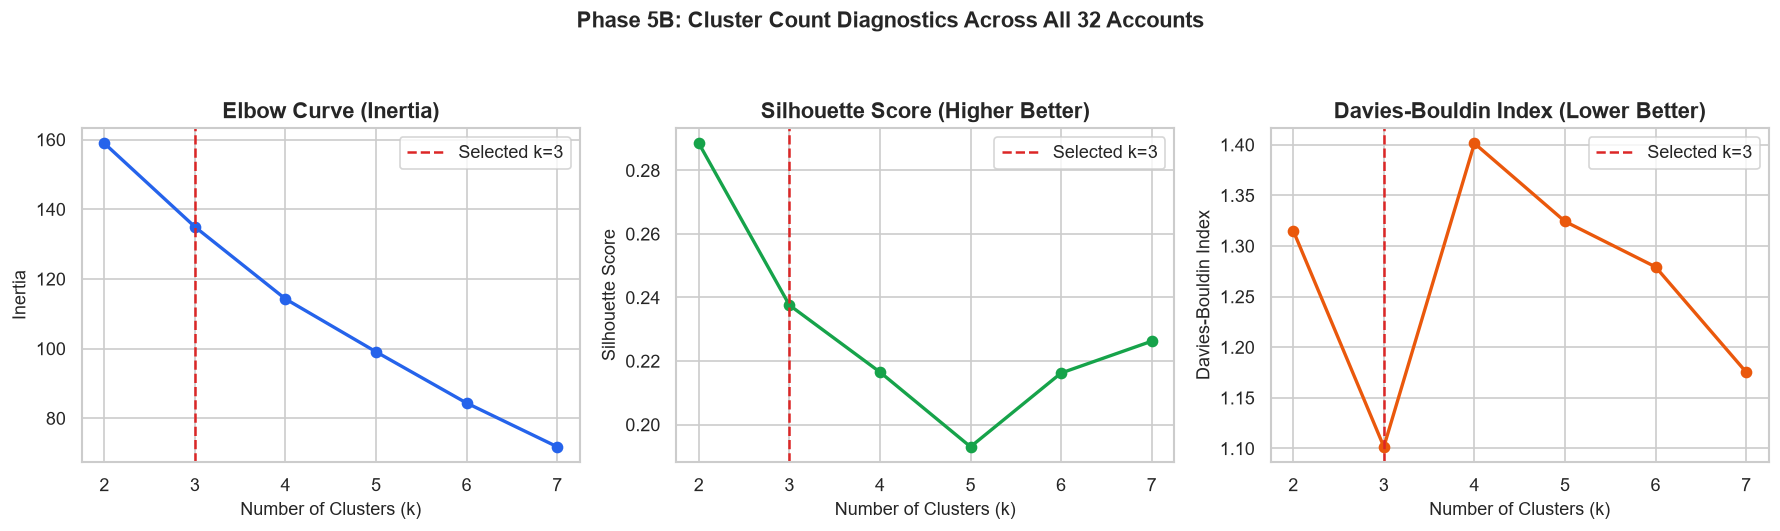

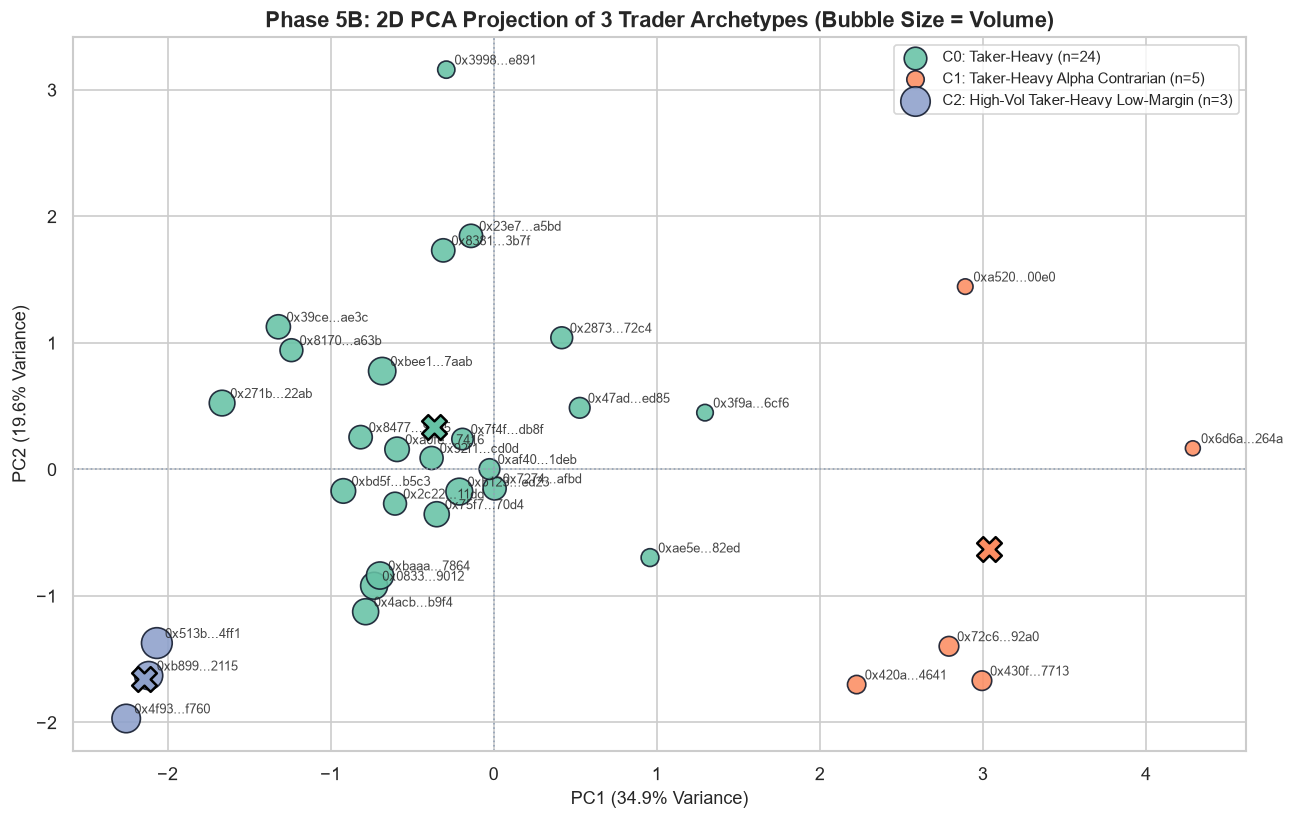

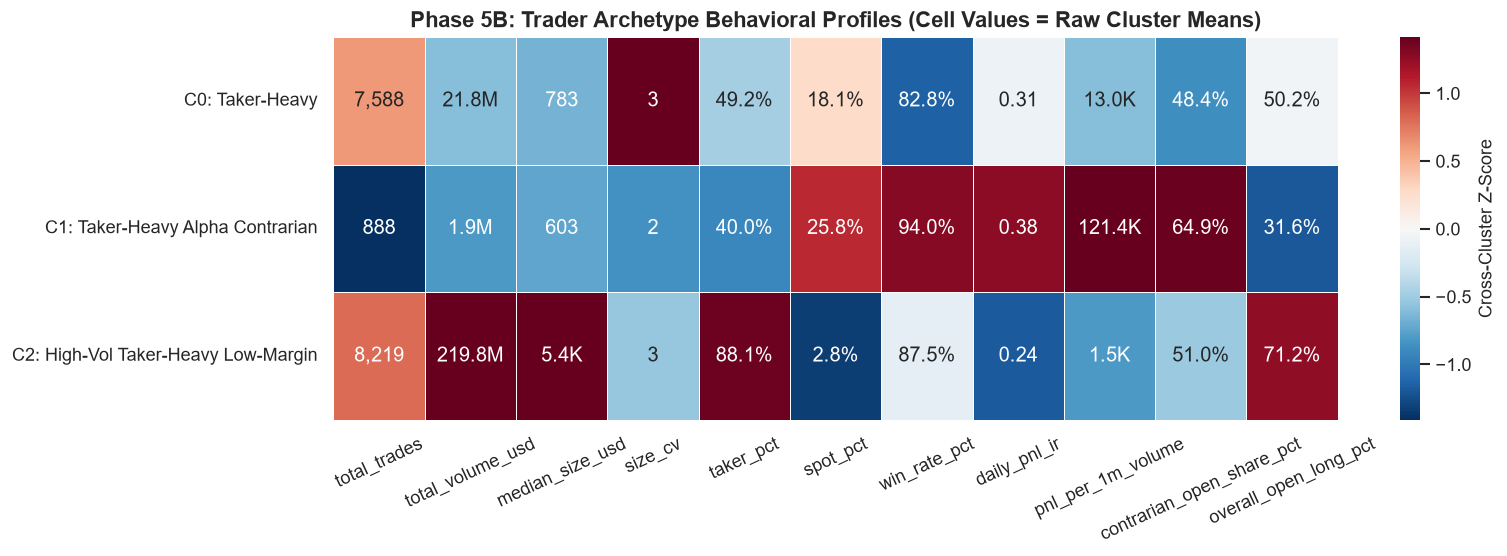

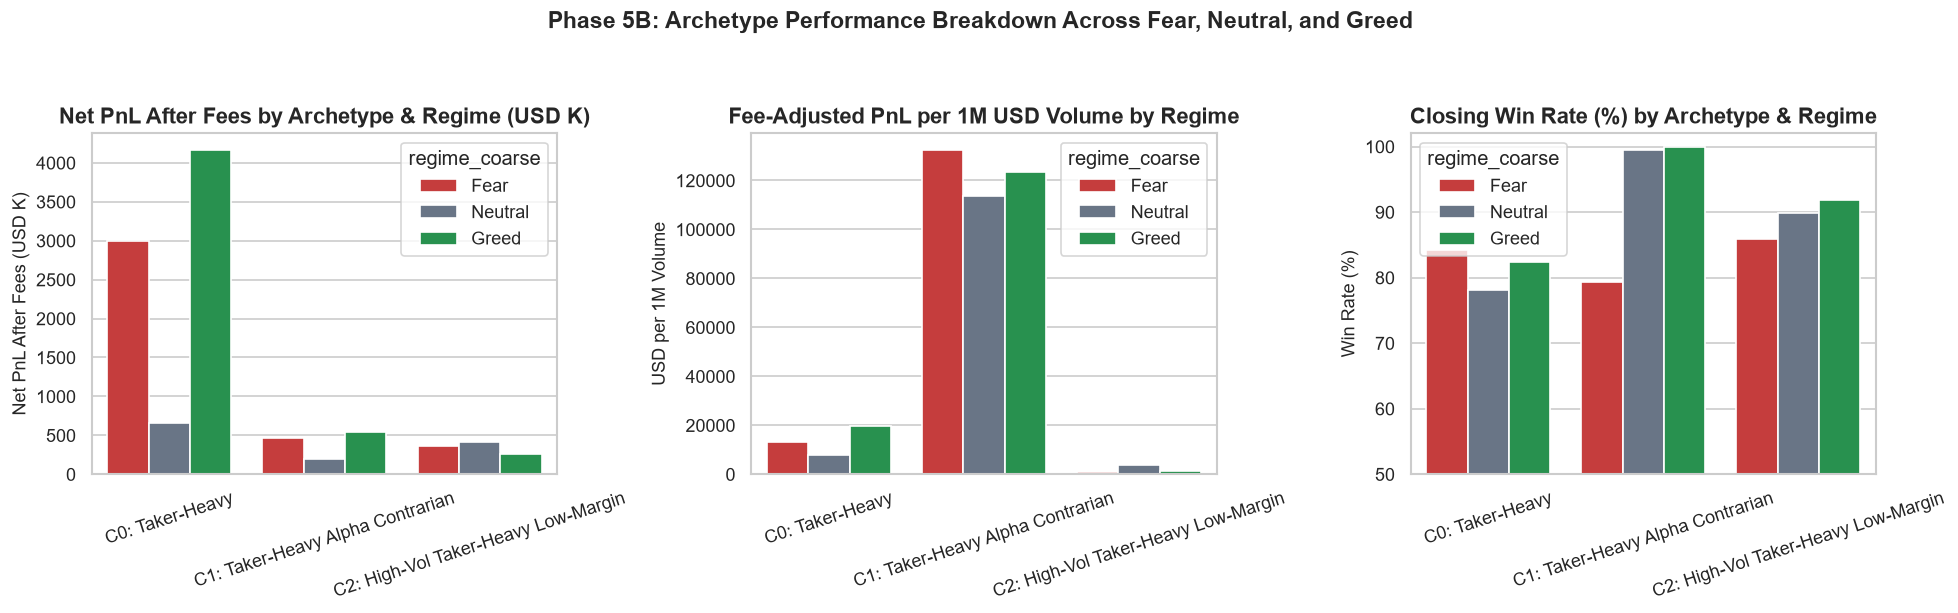

In [4]:
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# All 32 accounts have >= 332 trades, so zero low-activity exclusions are needed.
# Use 32/32 complete behavioral metrics (avoid profit_factor [4 NaNs] & contrarian_bias_shift [1 NaN] in clustering matrix).
df_seg = df_traders.copy()
df_seg['log1p_trades'] = np.log1p(df_seg['total_trades'])
df_seg['log1p_volume'] = np.log1p(df_seg['total_volume_usd'])
df_seg['log1p_med_size'] = np.log1p(df_seg['median_size_usd'])

CLUSTER_FEATURES = [
    'log1p_trades',
    'log1p_volume',
    'log1p_med_size',
    'size_cv',
    'taker_pct',
    'spot_pct',
    'win_rate_pct',
    'daily_pnl_ir',
    'pnl_per_1m_volume',
    'contrarian_open_share_pct',
    'overall_open_long_pct',
]

X_raw = df_seg[CLUSTER_FEATURES].copy()
assert X_raw.isna().sum().sum() == 0, f'Unexpected NaNs in cluster features: {X_raw.isna().sum()}'

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_raw)

# Evaluate k = 2..7
k_records = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=25)
    labels_k = km.fit_predict(X_scaled)
    k_records.append({
        'k': k,
        'inertia': float(km.inertia_),
        'silhouette': float(silhouette_score(X_scaled, labels_k)),
        'davies_bouldin': float(davies_bouldin_score(X_scaled, labels_k)),
        'calinski_harabasz': float(calinski_harabasz_score(X_scaled, labels_k)),
    })
df_k_eval = pd.DataFrame(k_records)
display(df_k_eval)

# Select k in [3, 4, 5] maximizing Silhouette Score for granular non-binary archetypes
cand_k = df_k_eval[df_k_eval['k'].isin([3, 4, 5])]
k_opt = int(cand_k.loc[cand_k['silhouette'].idxmax(), 'k'])
print(f'Selected optimal k={k_opt} (Silhouette={cand_k["silhouette"].max():.3f}, DB={cand_k.loc[cand_k["k"] == k_opt, "davies_bouldin"].iloc[0]:.3f})')

# Plot K selection diagnostics (08_clusters_k_selection.png)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(df_k_eval['k'], df_k_eval['inertia'], marker='o', color='#2563eb', linewidth=2)
axes[0].axvline(k_opt, color='#dc2626', linestyle='--', label=f'Selected k={k_opt}')
axes[0].set_title('Elbow Curve (Inertia)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].legend()

axes[1].plot(df_k_eval['k'], df_k_eval['silhouette'], marker='o', color='#16a34a', linewidth=2)
axes[1].axvline(k_opt, color='#dc2626', linestyle='--', label=f'Selected k={k_opt}')
axes[1].set_title('Silhouette Score (Higher Better)', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

axes[2].plot(df_k_eval['k'], df_k_eval['davies_bouldin'], marker='o', color='#ea580c', linewidth=2)
axes[2].axvline(k_opt, color='#dc2626', linestyle='--', label=f'Selected k={k_opt}')
axes[2].set_title('Davies-Bouldin Index (Lower Better)', fontweight='bold')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].legend()

fig.suptitle('Phase 5B: Cluster Count Diagnostics Across All 32 Accounts', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.93])
save_fig(fig, '08_clusters_k_selection.png')

# Fit final KMeans & PCA
km_final = KMeans(n_clusters=k_opt, random_state=RANDOM_STATE, n_init=25)
df_seg['cluster_id'] = km_final.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
df_seg['pca_1'] = pcs[:, 0]
df_seg['pca_2'] = pcs[:, 1]
exp_var = 100.0 * pca.explained_variance_ratio_

# Deterministic interpretable archetype naming based on cluster centroids
global_med = df_seg[['total_volume_usd', 'taker_pct', 'spot_pct', 'daily_pnl_ir', 'contrarian_open_share_pct', 'pnl_per_1m_volume']].median()
cluster_means = df_seg.groupby('cluster_id')[[
    'total_trades', 'total_volume_usd', 'median_size_usd', 'taker_pct', 'spot_pct',
    'win_rate_pct', 'daily_pnl_ir', 'pnl_per_1m_volume', 'net_pnl_after_fees',
    'contrarian_open_share_pct', 'overall_open_long_pct'
]].mean()

def build_archetype_name(cid, row):
    tags = []
    if row['total_volume_usd'] >= global_med['total_volume_usd'] * 2.0:
        tags.append('High-Vol')
    if row['spot_pct'] >= 30.0:
        tags.append('Spot-Active')
    elif row['taker_pct'] < 40.0:
        tags.append('Maker-Heavy')
    else:
        tags.append('Taker-Heavy')
    if row['daily_pnl_ir'] >= 0.35 and row['pnl_per_1m_volume'] >= 20000:
        tags.append('Alpha')
    elif row['pnl_per_1m_volume'] < 5000:
        tags.append('Low-Margin')
    if row['contrarian_open_share_pct'] >= 58.0:
        tags.append('Contrarian')
    elif row['contrarian_open_share_pct'] <= 42.0:
        tags.append('Momentum')
    label_core = ' '.join(tags[:3]) if tags else 'Balanced'
    return f'C{cid}: {label_core}'

archetype_map = {int(cid): build_archetype_name(int(cid), row) for cid, row in cluster_means.iterrows()}
df_seg['archetype'] = df_seg['cluster_id'].map(archetype_map)

# Export clustered trader profiles (32 rows)
export_csv(df_seg, '06_trader_clusters.csv')

# Post-hoc cluster summary including metrics excluded from scaling (profit_factor, contrarian_bias_shift) & Fear/Greed splits
cluster_summary_rows = []
for cid in sorted(archetype_map.keys()):
    sub = df_seg[df_seg['cluster_id'] == cid]
    cluster_summary_rows.append({
        'cluster_id': cid,
        'archetype': archetype_map[cid],
        'n_accounts': int(len(sub)),
        'total_trades_sum': int(sub['total_trades'].sum()),
        'total_volume_usd_sum': float(sub['total_volume_usd'].sum()),
        'net_pnl_after_fees_sum': float(sub['net_pnl_after_fees'].sum()),
        'mean_median_size_usd': float(sub['median_size_usd'].mean()),
        'mean_taker_pct': float(sub['taker_pct'].mean()),
        'mean_spot_pct': float(sub['spot_pct'].mean()),
        'mean_win_rate_pct': float(sub['win_rate_pct'].mean()),
        'mean_daily_pnl_ir': float(sub['daily_pnl_ir'].mean()),
        'mean_pnl_per_1m_vol': float(sub['pnl_per_1m_volume'].mean()),
        'mean_max_dd_usd': float(sub['max_daily_drawdown_usd'].mean()),
        'mean_contrarian_pct': float(sub['contrarian_open_share_pct'].mean()),
        'mean_profit_factor_finite': float(sub['profit_factor'].dropna().mean()) if sub['profit_factor'].notna().any() else np.nan,
        'mean_bias_shift_finite': float(sub['contrarian_bias_shift'].dropna().mean()) if sub['contrarian_bias_shift'].notna().any() else np.nan,
        'mean_fear_pnl_per_1m': float(sub['fear_pnl_per_1m_vol'].dropna().mean()),
        'mean_greed_pnl_per_1m': float(sub['greed_pnl_per_1m_vol'].dropna().mean()),
    })
df_cluster_sum = pd.DataFrame(cluster_summary_rows)
export_csv(df_cluster_sum, '06_cluster_summary.csv')
display(df_cluster_sum)

# --- Plot 1: 2D PCA Cluster Projection (08_clusters_projection.png) ---
fig, ax = plt.subplots(figsize=(11, 7))
cluster_palette = sns.color_palette('Set2', n_colors=k_opt)
for idx, cid in enumerate(sorted(archetype_map.keys())):
    sub = df_seg[df_seg['cluster_id'] == cid]
    sizes = 80 + 260 * (sub['log1p_volume'] - df_seg['log1p_volume'].min()) / max(1e-6, (df_seg['log1p_volume'].max() - df_seg['log1p_volume'].min()))
    ax.scatter(sub['pca_1'], sub['pca_2'], s=sizes, color=cluster_palette[idx], edgecolor='#0f172a', linewidth=1.0, alpha=0.88, label=f"{archetype_map[cid]} (n={len(sub)})")
    for _, r in sub.iterrows():
        ax.text(r['pca_1'] + 0.05, r['pca_2'] + 0.04, r['short_acct'], fontsize=7.5, alpha=0.85)
    # Centroid marker
    ax.scatter([sub['pca_1'].mean()], [sub['pca_2'].mean()], marker='X', s=220, color=cluster_palette[idx], edgecolor='black', linewidth=1.5, zorder=5)

ax.axhline(0, color='#94a3b8', linestyle=':', linewidth=1)
ax.axvline(0, color='#94a3b8', linestyle=':', linewidth=1)
ax.set_xlabel(f'PC1 ({exp_var[0]:.1f}% Variance)')
ax.set_ylabel(f'PC2 ({exp_var[1]:.1f}% Variance)')
ax.set_title(f'Phase 5B: 2D PCA Projection of {k_opt} Trader Archetypes (Bubble Size = Volume)', fontweight='bold')
ax.legend(loc='best', frameon=True, fontsize=9)
fig.tight_layout()
save_fig(fig, '08_clusters_projection.png')

# --- Plot 2: Normalized Cluster Feature Profiles Heatmap (08_clusters_profiles.png) ---
prof_cols = [
    'total_trades', 'total_volume_usd', 'median_size_usd', 'size_cv',
    'taker_pct', 'spot_pct', 'win_rate_pct', 'daily_pnl_ir',
    'pnl_per_1m_volume', 'contrarian_open_share_pct', 'overall_open_long_pct'
]
c_means_full = df_seg.groupby('archetype')[prof_cols].mean()
c_z = (c_means_full - c_means_full.mean()) / c_means_full.std(ddof=0).replace(0, 1.0)

fig, ax = plt.subplots(figsize=(13.5, 4.8))
annot_text = c_means_full.copy().astype(str)
for col in prof_cols:
    if 'volume' in col or 'size' in col or 'pnl_per' in col:
        annot_text[col] = c_means_full[col].map(lambda v: f'{v/1e6:.1f}M' if abs(v) >= 1e6 else (f'{v/1e3:.1f}K' if abs(v) >= 1e3 else f'{v:.0f}'))
    elif 'pct' in col:
        annot_text[col] = c_means_full[col].map(lambda v: f'{v:.1f}%')
    elif col == 'total_trades':
        annot_text[col] = c_means_full[col].map(lambda v: f'{v:,.0f}')
    else:
        annot_text[col] = c_means_full[col].map(lambda v: f'{v:.2f}')

sns.heatmap(c_z, annot=annot_text, fmt='', cmap='RdBu_r', center=0, linewidths=0.6, ax=ax, cbar_kws={'label': 'Cross-Cluster Z-Score'})
ax.set_title('Phase 5B: Trader Archetype Behavioral Profiles (Cell Values = Raw Cluster Means)', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
save_fig(fig, '08_clusters_profiles.png')

# --- Plot 3: Archetype Performance Across Market Regimes (08_clusters_regime_performance.png) ---
acct_to_arch = df_seg.set_index('account')['archetype'].to_dict()
df_trades['archetype'] = df_trades['account'].map(acct_to_arch)

arch_reg_rows = []
for (arch, reg), g in df_trades.groupby(['archetype', 'regime_coarse'], observed=True):
    vol = g['size_usd'].sum()
    net_after = g['net_pnl_after_fee'].sum()
    cls_g = g[g['is_closing_trade']]
    op_g = g[g['is_perp_open']]
    arch_reg_rows.append({
        'archetype': arch,
        'regime_coarse': reg,
        'trades': int(len(g)),
        'volume_usd_m': float(vol / 1e6),
        'net_pnl_after_fee_k': float(net_after / 1e3),
        'pnl_per_1m_vol': float(1e6 * net_after / vol) if vol > 0 else np.nan,
        'win_rate_pct': float(100.0 * cls_g['is_win'].mean()) if len(cls_g) > 0 else np.nan,
        'contrarian_pct': float(100.0 * op_g['is_contrarian_open'].mean()) if (reg in ['Fear', 'Greed'] and len(op_g) > 0) else np.nan,
    })
df_arch_reg = pd.DataFrame(arch_reg_rows)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))
sns.barplot(data=df_arch_reg, x='archetype', y='net_pnl_after_fee_k', hue='regime_coarse', hue_order=COARSE_ORDER, palette=COARSE_COLORS, ax=axes[0])
axes[0].axhline(0, color='black', linewidth=0.9)
axes[0].set_title('Net PnL After Fees by Archetype & Regime (USD K)', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Net PnL After Fees (USD K)')
axes[0].tick_params(axis='x', rotation=18)

sns.barplot(data=df_arch_reg, x='archetype', y='pnl_per_1m_vol', hue='regime_coarse', hue_order=COARSE_ORDER, palette=COARSE_COLORS, ax=axes[1])
axes[1].axhline(0, color='black', linewidth=0.9)
axes[1].set_title('Fee-Adjusted PnL per 1M USD Volume by Regime', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('USD per 1M Volume')
axes[1].tick_params(axis='x', rotation=18)

sns.barplot(data=df_arch_reg, x='archetype', y='win_rate_pct', hue='regime_coarse', hue_order=COARSE_ORDER, palette=COARSE_COLORS, ax=axes[2])
axes[2].set_title('Closing Win Rate (%) by Archetype & Regime', fontweight='bold')
axes[2].set_xlabel('')
axes[2].set_ylabel('Win Rate (%)')
axes[2].set_ylim(50, 102)
axes[2].tick_params(axis='x', rotation=18)

fig.suptitle('Phase 5B: Archetype Performance Breakdown Across Fear, Neutral, and Greed', fontsize=13.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.93])
save_fig(fig, '08_clusters_regime_performance.png')
print('Phase 5B complete: exported 06_trader_clusters.csv, 06_cluster_summary.csv, and 08_clusters_*.png')

---
## 4. Phase 5C: Regime-Transition Event Studies & Strategy Signals

- Event study around sentiment shifts ($t-3 \dots t+5$).
- Contrarian vs Momentum strategy comparison and drawdown curves.
- Optional time-aware predictive check & feature importance.
- Save `outputs/09_signals_*.png`.

Calendar regime transition events in active span (2023-04-30..2025-05-01): Shift->Fear=31, Shift->Greed=26
[Saved Image] outputs\09_signals_regime_transition_event_study.png
[Saved Image] outputs\09_signals_contrarian_vs_momentum.png


,target,model,n_rows,n_valid_folds,cv_roc_auc_mean,cv_roc_auc_std,cv_bal_acc_mean
0,target_high_vol,LogisticRegression,352,5,0.578751,0.159423,0.540330
1,target_high_vol,RandomForest,352,5,0.502745,0.115694,0.515100
2,target_profitable,LogisticRegression,352,5,0.581879,0.090586,0.502349
3,target_profitable,RandomForest,352,5,0.485629,0.128858,0.504341


[Saved CSV] csv_files\07_signals_summary.csv | shape=(11, 7)
[Saved Image] outputs\09_signals_feature_importance.png
Phase 5C complete: exported 07_signals_summary.csv and 09_signals_*.png


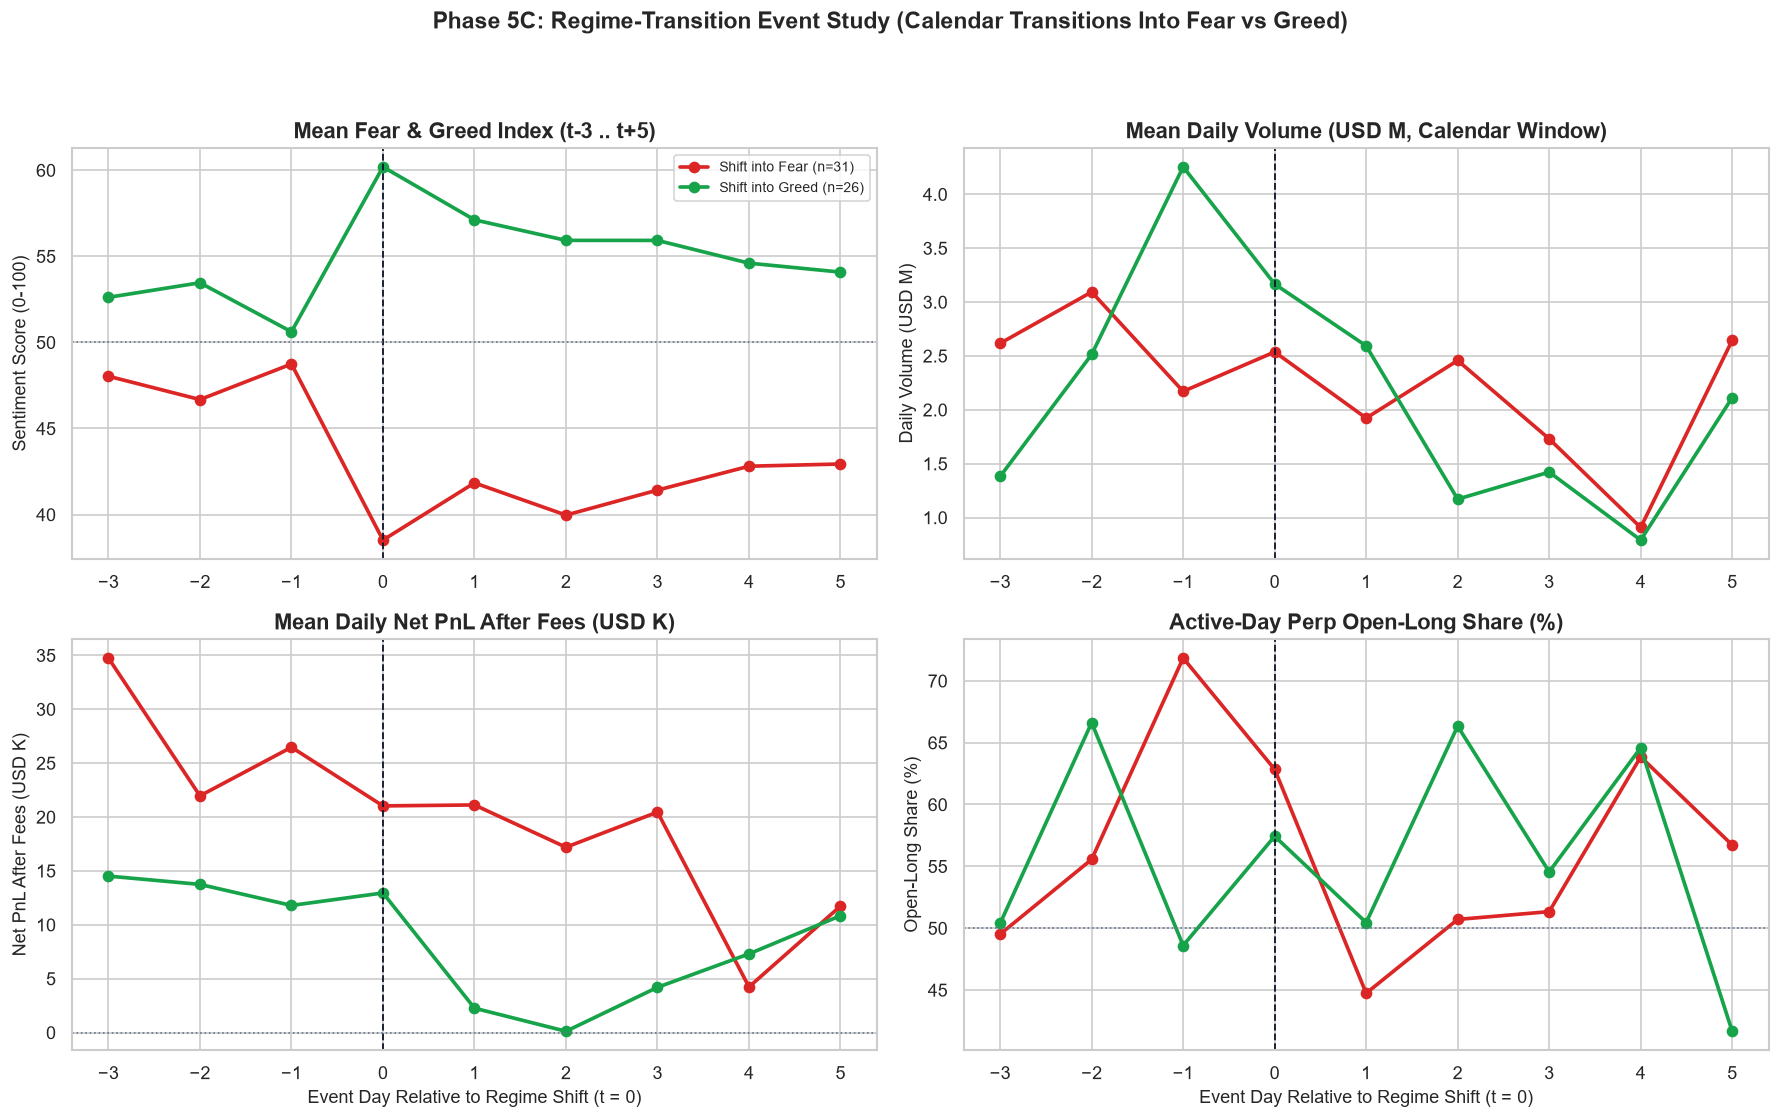

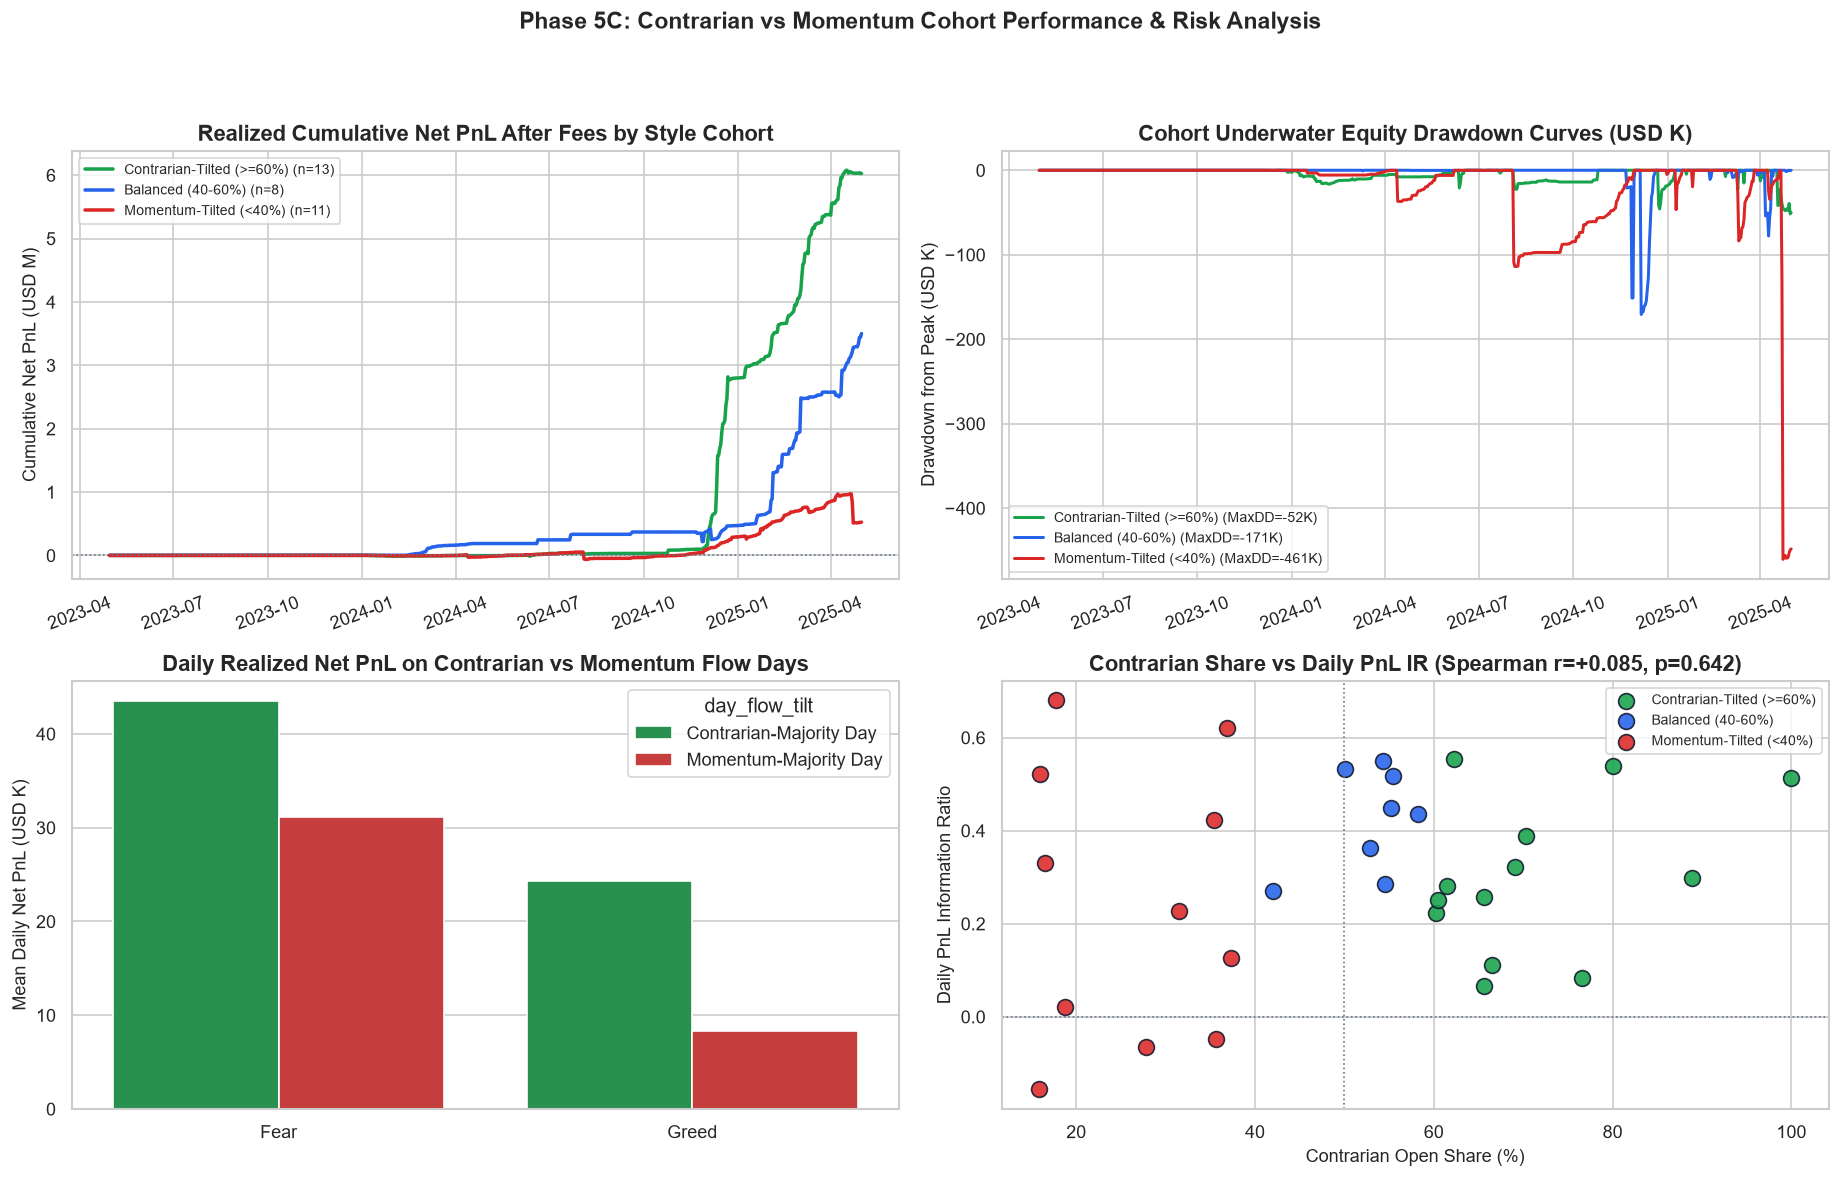

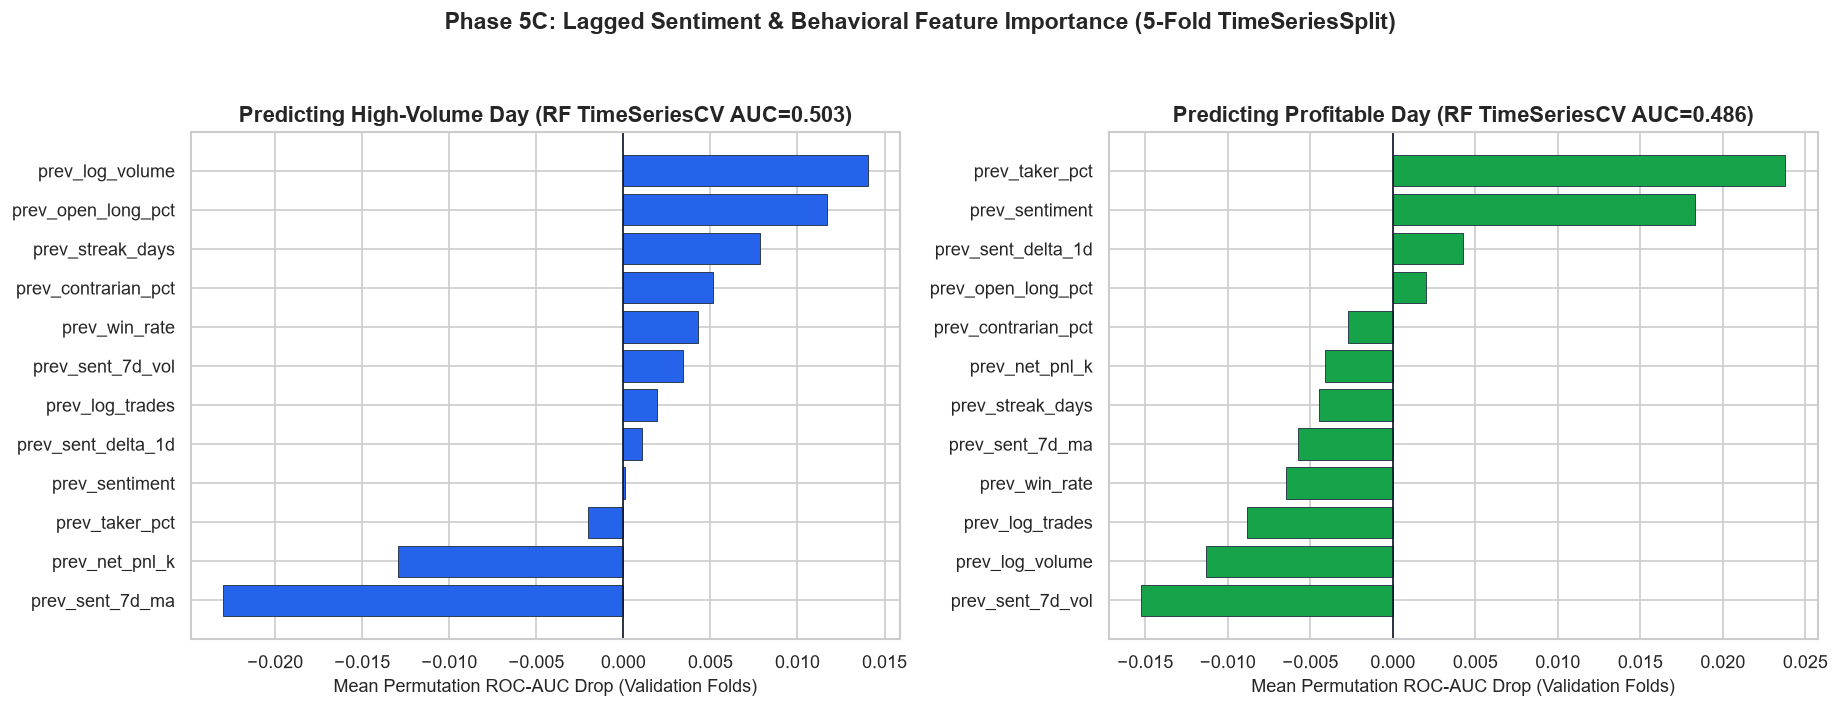

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.inspection import permutation_importance

# ============================================================================
# 1. REGIME-TRANSITION EVENT STUDY (t-3 .. t+5 calendar days)
# ============================================================================
cal_start = df_daily['trade_date_dt'].min()
cal_end = df_daily['trade_date_dt'].max()
cal_idx = pd.date_range(cal_start, cal_end, freq='D')

df_cal = pd.DataFrame({'date_dt': cal_idx}).merge(
    df_sent_clean[['date_dt', 'value', 'classification', 'regime_coarse', 'sentiment_delta_1d']],
    on='date_dt',
    how='left',
).merge(
    df_daily[['trade_date_dt', 'trade_count', 'total_volume_usd', 'net_pnl_after_fees', 'win_rate_pct', 'taker_pct', 'open_long_share_pct']],
    left_on='date_dt',
    right_on='trade_date_dt',
    how='left',
)
df_cal['is_active_day'] = df_cal['trade_count'].notna()
df_cal['prev_coarse'] = df_cal['regime_coarse'].shift(1)
# Fill calendar inactive days with 0 for flow metrics (volume, trades, pnl); leave rate metrics NaN
for flow_col in ['trade_count', 'total_volume_usd', 'net_pnl_after_fees']:
    df_cal[flow_col] = df_cal[flow_col].fillna(0.0)

fear_entries = df_cal.index[(df_cal['regime_coarse'] == 'Fear') & (df_cal['prev_coarse'].isin(['Neutral', 'Greed']))].tolist()
greed_entries = df_cal.index[(df_cal['regime_coarse'] == 'Greed') & (df_cal['prev_coarse'].isin(['Neutral', 'Fear']))].tolist()
print(f'Calendar regime transition events in active span ({cal_start.date()}..{cal_end.date()}): Shift->Fear={len(fear_entries)}, Shift->Greed={len(greed_entries)}')

def extract_event_window(event_indices, label, window=range(-3, 6)):
    rows = []
    n_max = len(df_cal)
    for tau in window:
        valid_idx = [idx + tau for idx in event_indices if 0 <= (idx + tau) < n_max]
        sub = df_cal.iloc[valid_idx]
        active_sub = sub[sub['is_active_day']]
        rows.append({
            'event_type': label,
            'tau': int(tau),
            'n_events': int(len(sub)),
            'n_active': int(len(active_sub)),
            'mean_sentiment': float(sub['value'].mean()),
            'mean_volume_usd_m': float(sub['total_volume_usd'].mean() / 1e6),
            'mean_trade_count': float(sub['trade_count'].mean()),
            'mean_net_pnl_k': float(sub['net_pnl_after_fees'].mean() / 1e3),
            'mean_open_long_pct': float(active_sub['open_long_share_pct'].mean()) if len(active_sub) > 0 else np.nan,
            'mean_taker_pct': float(active_sub['taker_pct'].mean()) if len(active_sub) > 0 else np.nan,
        })
    out = pd.DataFrame(rows)
    base_vol = out.loc[out['tau'].isin([-3, -2, -1]), 'mean_volume_usd_m'].mean()
    out['volume_vs_pre_ratio'] = out['mean_volume_usd_m'] / base_vol if base_vol > 0 else np.nan
    return out

df_evt = pd.concat([
    extract_event_window(fear_entries, f'Shift into Fear (n={len(fear_entries)})'),
    extract_event_window(greed_entries, f'Shift into Greed (n={len(greed_entries)})'),
], ignore_index=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
evt_colors = {f'Shift into Fear (n={len(fear_entries)})': '#dc2626', f'Shift into Greed (n={len(greed_entries)})': '#16a34a'}
for label, g in df_evt.groupby('event_type'):
    c = evt_colors[label]
    axes[0, 0].plot(g['tau'], g['mean_sentiment'], marker='o', linewidth=2.2, color=c, label=label)
    axes[0, 1].plot(g['tau'], g['mean_volume_usd_m'], marker='o', linewidth=2.2, color=c, label=label)
    axes[1, 0].plot(g['tau'], g['mean_net_pnl_k'], marker='o', linewidth=2.2, color=c, label=label)
    axes[1, 1].plot(g['tau'], g['mean_open_long_pct'], marker='o', linewidth=2.2, color=c, label=label)

for ax in axes.flat:
    ax.axvline(0, color='#0f172a', linestyle='--', linewidth=1.1)
    ax.set_xticks(list(range(-3, 6)))
axes[0, 0].axhline(50, color='#64748b', linestyle=':', linewidth=1)
axes[0, 0].set_title('Mean Fear & Greed Index (t-3 .. t+5)', fontweight='bold')
axes[0, 0].set_ylabel('Sentiment Score (0-100)')
axes[0, 0].legend(fontsize=8.5)

axes[0, 1].set_title('Mean Daily Volume (USD M, Calendar Window)', fontweight='bold')
axes[0, 1].set_ylabel('Daily Volume (USD M)')

axes[1, 0].axhline(0, color='#64748b', linestyle=':', linewidth=1)
axes[1, 0].set_title('Mean Daily Net PnL After Fees (USD K)', fontweight='bold')
axes[1, 0].set_xlabel('Event Day Relative to Regime Shift (t = 0)')
axes[1, 0].set_ylabel('Net PnL After Fees (USD K)')

axes[1, 1].axhline(50, color='#64748b', linestyle=':', linewidth=1)
axes[1, 1].set_title('Active-Day Perp Open-Long Share (%)', fontweight='bold')
axes[1, 1].set_xlabel('Event Day Relative to Regime Shift (t = 0)')
axes[1, 1].set_ylabel('Open-Long Share (%)')

fig.suptitle('Phase 5C: Regime-Transition Event Study (Calendar Transitions Into Fear vs Greed)', fontsize=13.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, '09_signals_regime_transition_event_study.png')

# ============================================================================
# 2. CONTRARIAN VS MOMENTUM COHORT EQUITY CURVES & DRAWDOWN ANALYSIS
# ============================================================================
# Classify 32 traders cleanly by overall contrarian open share:
# Contrarian-Tilted (>=60%), Balanced (40-60%), Momentum-Tilted (<40%)
def assign_style_cohort(pct):
    if pct >= 60.0:
        return 'Contrarian-Tilted (>=60%)'
    if pct < 40.0:
        return 'Momentum-Tilted (<40%)'
    return 'Balanced (40-60%)'

df_seg['style_cohort'] = df_seg['contrarian_open_share_pct'].map(assign_style_cohort)
acct_style = df_seg.set_index('account')['style_cohort'].to_dict()
df_trades['style_cohort'] = df_trades['account'].map(acct_style)

cohort_daily = (
    df_trades.groupby(['trade_date_dt', 'style_cohort'], observed=True)
    .agg(net_pnl=('net_pnl_after_fee', 'sum'), volume=('size_usd', 'sum'))
    .reset_index()
)
piv_pnl = cohort_daily.pivot(index='trade_date_dt', columns='style_cohort', values='net_pnl').fillna(0.0).sort_index()
piv_vol = cohort_daily.pivot(index='trade_date_dt', columns='style_cohort', values='volume').fillna(0.0).sort_index()

cum_pnl = piv_pnl.cumsum()
dd_usd = cum_pnl - cum_pnl.cummax()
cohort_order = [c for c in ['Contrarian-Tilted (>=60%)', 'Balanced (40-60%)', 'Momentum-Tilted (<40%)'] if c in cum_pnl.columns]
cohort_colors = {'Contrarian-Tilted (>=60%)': '#16a34a', 'Balanced (40-60%)': '#2563eb', 'Momentum-Tilted (<40%)': '#dc2626'}

# Daily Fear/Greed contrarian-majority vs momentum-majority day realized performance
df_fg_days = df_daily[df_daily['regime_coarse'].isin(['Fear', 'Greed']) & df_daily['contrarian_open_pct'].notna()].copy()
df_fg_days['day_flow_tilt'] = np.where(df_fg_days['contrarian_open_pct'] >= 50.0, 'Contrarian-Majority Day', 'Momentum-Majority Day')
day_tilt_sum = df_fg_days.groupby(['regime_coarse', 'day_flow_tilt'], observed=True).agg(
    days=('trade_date_utc', 'count'),
    mean_win_rate=('win_rate_pct', 'mean'),
    mean_pnl_k=('net_pnl_after_fees', lambda s: s.mean() / 1e3),
).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(15.5, 10))
for coh in cohort_order:
    n_ac = int((df_seg['style_cohort'] == coh).sum())
    axes[0, 0].plot(cum_pnl.index, cum_pnl[coh] / 1e6, linewidth=2.1, color=cohort_colors[coh], label=f'{coh} (n={n_ac})')
    axes[0, 1].plot(dd_usd.index, dd_usd[coh] / 1e3, linewidth=1.8, color=cohort_colors[coh], label=f'{coh} (MaxDD={dd_usd[coh].min()/1e3:,.0f}K)')

axes[0, 0].axhline(0, color='#64748b', linestyle=':', linewidth=1)
axes[0, 0].set_title('Realized Cumulative Net PnL After Fees by Style Cohort', fontweight='bold')
axes[0, 0].set_ylabel('Cumulative Net PnL (USD M)')
axes[0, 0].legend(fontsize=8.5)
axes[0, 0].tick_params(axis='x', rotation=20)

axes[0, 1].set_title('Cohort Underwater Equity Drawdown Curves (USD K)', fontweight='bold')
axes[0, 1].set_ylabel('Drawdown from Peak (USD K)')
axes[0, 1].legend(fontsize=8.5, loc='lower left')
axes[0, 1].tick_params(axis='x', rotation=20)

sns.barplot(data=day_tilt_sum, x='regime_coarse', y='mean_pnl_k', hue='day_flow_tilt', order=['Fear', 'Greed'], palette={'Contrarian-Majority Day': '#16a34a', 'Momentum-Majority Day': '#dc2626'}, ax=axes[1, 0])
axes[1, 0].axhline(0, color='black', linewidth=0.9)
axes[1, 0].set_title('Daily Realized Net PnL on Contrarian vs Momentum Flow Days', fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Mean Daily Net PnL (USD K)')

for coh in cohort_order:
    sub = df_seg[df_seg['style_cohort'] == coh]
    axes[1, 1].scatter(sub['contrarian_open_share_pct'], sub['daily_pnl_ir'], s=90, color=cohort_colors[coh], edgecolor='#0f172a', alpha=0.88, label=coh)
r_ir, p_ir = stats.spearmanr(df_seg['contrarian_open_share_pct'], df_seg['daily_pnl_ir'])
axes[1, 1].axhline(0, color='#64748b', linestyle=':', linewidth=1)
axes[1, 1].axvline(50, color='#64748b', linestyle=':', linewidth=1)
axes[1, 1].set_title(f'Contrarian Share vs Daily PnL IR (Spearman r={r_ir:+.3f}, p={p_ir:.3f})', fontweight='bold')
axes[1, 1].set_xlabel('Contrarian Open Share (%)')
axes[1, 1].set_ylabel('Daily PnL Information Ratio')
axes[1, 1].legend(fontsize=8.5, loc='best')

fig.suptitle('Phase 5C: Contrarian vs Momentum Cohort Performance & Risk Analysis', fontsize=13.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, '09_signals_contrarian_vs_momentum.png')

# ============================================================================
# 3. TIME-AWARE PREDICTIVE CHECK (TimeSeriesSplit CV, ZERO LOOK-AHEAD)
# ============================================================================
df_ml = df_daily.sort_values('trade_date_dt').copy()
df_ml['prev_log_trades'] = np.log1p(df_ml['trade_count'].shift(1))
df_ml['prev_log_volume'] = np.log1p(df_ml['total_volume_usd'].shift(1))
df_ml['prev_net_pnl_k'] = df_ml['net_pnl_after_fees'].shift(1) / 1e3
df_ml['prev_win_rate'] = df_ml['win_rate_pct'].shift(1)
df_ml['prev_taker_pct'] = df_ml['taker_pct'].shift(1)
df_ml['prev_open_long_pct'] = df_ml['open_long_share_pct'].shift(1)
df_ml['prev_contrarian_pct'] = df_ml['contrarian_open_pct'].shift(1)
df_ml['prev_sentiment'] = df_ml['sentiment_value_lag1']
df_ml['prev_sent_delta_1d'] = df_ml['sentiment_delta_1d'].shift(1)
df_ml['prev_sent_7d_ma'] = df_ml['sentiment_7d_ma'].shift(1)
df_ml['prev_sent_7d_vol'] = df_ml['sentiment_7d_vol'].shift(1)
df_ml['prev_streak_days'] = df_ml['regime_streak_days'].shift(1)

PRED_FEATURES = [
    'prev_log_trades', 'prev_log_volume', 'prev_net_pnl_k', 'prev_win_rate',
    'prev_taker_pct', 'prev_open_long_pct', 'prev_contrarian_pct',
    'prev_sentiment', 'prev_sent_delta_1d', 'prev_sent_7d_ma', 'prev_sent_7d_vol', 'prev_streak_days'
]

# Targets: (A) High-Volume Day (> trailing 30d expanding/rolling median shifted by 1), (B) Profitable Day (net_pnl_after_fees > 0)
df_ml['trailing_med_vol'] = df_ml['total_volume_usd'].shift(1).rolling(30, min_periods=10).median()
df_ml['target_high_vol'] = (df_ml['total_volume_usd'] > df_ml['trailing_med_vol']).astype(float)
df_ml['target_profitable'] = (df_ml['net_pnl_after_fees'] > 0).astype(int)

df_ml_clean = df_ml.dropna(subset=PRED_FEATURES + ['trailing_med_vol']).reset_index(drop=True)
X_ml = df_ml_clean[PRED_FEATURES]
tscv = TimeSeriesSplit(n_splits=5)

def eval_tscv(target_col, model_name, estimator):
    y = df_ml_clean[target_col].astype(int)
    aucs, baccs = [], []
    imp_folds = []
    for tr_idx, te_idx in tscv.split(X_ml):
        X_tr, X_te = X_ml.iloc[tr_idx], X_ml.iloc[te_idx]
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]
        if len(np.unique(y_tr)) < 2 or len(np.unique(y_te)) < 2:
            continue
        estimator.fit(X_tr, y_tr)
        probs = estimator.predict_proba(X_te)[:, 1]
        preds = (probs >= 0.5).astype(int)
        aucs.append(roc_auc_score(y_te, probs))
        baccs.append(balanced_accuracy_score(y_te, preds))
        perm = permutation_importance(estimator, X_te, y_te, n_repeats=15, random_state=RANDOM_STATE, scoring='roc_auc')
        imp_folds.append(perm.importances_mean)
    mean_imp = np.mean(imp_folds, axis=0) if imp_folds else np.zeros(len(PRED_FEATURES))
    return {
        'target': target_col,
        'model': model_name,
        'n_rows': int(len(df_ml_clean)),
        'n_valid_folds': int(len(aucs)),
        'cv_roc_auc_mean': float(np.mean(aucs)),
        'cv_roc_auc_std': float(np.std(aucs)),
        'cv_bal_acc_mean': float(np.mean(baccs)),
        'importances': mean_imp,
    }

models_to_eval = [
    ('target_high_vol', 'LogisticRegression', Pipeline([('sc', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),),
    ('target_high_vol', 'RandomForest', RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=8, random_state=RANDOM_STATE)),
    ('target_profitable', 'LogisticRegression', Pipeline([('sc', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),),
    ('target_profitable', 'RandomForest', RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=8, random_state=RANDOM_STATE)),
]

cv_results = []
rf_high_vol_imp = None
rf_profit_imp = None
for tgt, mname, est in models_to_eval:
    out = eval_tscv(tgt, mname, est)
    imps = out.pop('importances')
    cv_results.append(out)
    if tgt == 'target_high_vol' and mname == 'RandomForest':
        rf_high_vol_imp = imps
    if tgt == 'target_profitable' and mname == 'RandomForest':
        rf_profit_imp = imps

df_cv = pd.DataFrame(cv_results)
display(df_cv)

df_imp = pd.DataFrame({
    'feature': PRED_FEATURES,
    'high_vol_perm_auc_drop': rf_high_vol_imp,
    'profitable_perm_auc_drop': rf_profit_imp,
}).sort_values('high_vol_perm_auc_drop', ascending=False)

# Export consolidated Phase 5C summary CSV
sig_rows = []
for _, r in df_cv.iterrows():
    sig_rows.append({
        'section': 'TimeSeriesCV_Model',
        'name': f"{r['target']} | {r['model']}",
        'metric_1_name': 'cv_roc_auc_mean',
        'metric_1_val': r['cv_roc_auc_mean'],
        'metric_2_name': 'cv_bal_acc_mean',
        'metric_2_val': r['cv_bal_acc_mean'],
        'n_obs': r['n_rows'],
    })
for _, r in day_tilt_sum.iterrows():
    sig_rows.append({
        'section': 'Daily_Flow_Tilt',
        'name': f"{r['regime_coarse']} | {r['day_flow_tilt']}",
        'metric_1_name': 'mean_win_rate_pct',
        'metric_1_val': float(r['mean_win_rate']),
        'metric_2_name': 'mean_pnl_k',
        'metric_2_val': float(r['mean_pnl_k']),
        'n_obs': int(r['days']),
    })
for coh in cohort_order:
    sig_rows.append({
        'section': 'Style_Cohort',
        'name': coh,
        'metric_1_name': 'cum_net_pnl_usd',
        'metric_1_val': float(cum_pnl[coh].iloc[-1]),
        'metric_2_name': 'max_drawdown_usd',
        'metric_2_val': float(dd_usd[coh].min()),
        'n_obs': int((df_seg['style_cohort'] == coh).sum()),
    })
df_sig_sum = pd.DataFrame(sig_rows)
export_csv(df_sig_sum, '07_signals_summary.csv')

# Plot Feature Importances & CV Performance (09_signals_feature_importance.png)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))
df_imp_sorted = df_imp.sort_values('high_vol_perm_auc_drop', ascending=True)
axes[0].barh(df_imp_sorted['feature'], df_imp_sorted['high_vol_perm_auc_drop'], color='#2563eb', edgecolor='#1e293b', linewidth=0.5)
axes[0].axvline(0, color='#0f172a', linewidth=1)
auc_hv = df_cv.loc[(df_cv['target'] == 'target_high_vol') & (df_cv['model'] == 'RandomForest'), 'cv_roc_auc_mean'].iloc[0]
axes[0].set_title(f'Predicting High-Volume Day (RF TimeSeriesCV AUC={auc_hv:.3f})', fontweight='bold')
axes[0].set_xlabel('Mean Permutation ROC-AUC Drop (Validation Folds)')

df_imp_p = df_imp.sort_values('profitable_perm_auc_drop', ascending=True)
axes[1].barh(df_imp_p['feature'], df_imp_p['profitable_perm_auc_drop'], color='#16a34a', edgecolor='#1e293b', linewidth=0.5)
axes[1].axvline(0, color='#0f172a', linewidth=1)
auc_pr = df_cv.loc[(df_cv['target'] == 'target_profitable') & (df_cv['model'] == 'RandomForest'), 'cv_roc_auc_mean'].iloc[0]
axes[1].set_title(f'Predicting Profitable Day (RF TimeSeriesCV AUC={auc_pr:.3f})', fontweight='bold')
axes[1].set_xlabel('Mean Permutation ROC-AUC Drop (Validation Folds)')

fig.suptitle('Phase 5C: Lagged Sentiment & Behavioral Feature Importance (5-Fold TimeSeriesSplit)', fontsize=13.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, '09_signals_feature_importance.png')
print('Phase 5C complete: exported 07_signals_summary.csv and 09_signals_*.png')

---
## 5. Phase 6: Insights Synthesis & Final Report (`ds_report.pdf`)

- Summarize validated insights, risk-management recommendations, and caveats.
- Compile curated `outputs/*.png` charts and key metrics into `ds_report.pdf`.

In [6]:
from fpdf import FPDF
from fpdf.enums import XPos, YPos
from PIL import Image

# Reload verified CSVs so Phase 6 can run standalone after kernel restart
rep_trades = pd.read_csv(CSV_DIR / '02_merged_trader_sentiment.csv', low_memory=False)
rep_daily = pd.read_csv(CSV_DIR / '03_features_daily_regime.csv')
rep_traders = pd.read_csv(CSV_DIR / '04_features_trader_profiles.csv')
rep_tests = pd.read_csv(CSV_DIR / '05_stats_regime_tests.csv')
rep_boot = pd.read_csv(CSV_DIR / '05_stats_bootstrap_ci.csv')
rep_clusters = pd.read_csv(CSV_DIR / '06_cluster_summary.csv')
rep_signals = pd.read_csv(CSV_DIR / '07_signals_summary.csv')

def latin1_safe(text):
    """Normalize Unicode punctuation/symbols cleanly to Latin-1 for core FPDF fonts."""
    repl = {
        '\u2014': '--', '\u2013': '-', '\u2212': '-', '\u2248': '~',
        '\u2192': '->', '\u2265': '>=', '\u2264': '<=', '\u00d7': 'x',
        '\u2022': '-', '\u2018': "'", '\u2019': "'", '\u201c': '"', '\u201d': '"',
        '\u0394': 'Delta', '\u2026': '...',
    }
    s = str(text)
    for k, v in repl.items():
        s = s.replace(k, v)
    return s.encode('latin-1', errors='replace').decode('latin-1')

# Compute exact KPIs directly from verified CSVs
tot_trades = len(rep_trades)
tot_accts = int(rep_trades['account'].nunique())
tot_coins = int(rep_trades['coin'].nunique())
tot_days = len(rep_daily)
tot_vol_usd = float(rep_trades['size_usd'].sum())
tot_gross_pnl = float(rep_trades['closed_pnl'].sum())
tot_fees_usd = float(rep_trades['fee'].sum())
tot_net_after_fees = tot_gross_pnl - tot_fees_usd
n_date_shifted = int(rep_trades['date_shifted_ist_to_utc'].sum())
close_mask = rep_trades['is_closing_trade'].astype(bool)
global_win_rate = 100.0 * float((rep_trades.loc[close_mask, 'closed_pnl'] > 0).mean())

n_sig_5reg = int(rep_tests['sig_5reg_fdr05'].sum())
n_sig_fg = int(rep_tests['sig_fg_fdr05'].sum())
n_tests_tot = len(rep_tests)

def get_test_row(level, metric):
    return rep_tests[(rep_tests['level'] == level) & (rep_tests['metric'] == metric)].iloc[0]

t_spot_day = get_test_row('Daily', 'spot_pct')
t_vol_day = get_test_row('Daily', 'total_volume_usd')
t_pnl_day = get_test_row('Daily', 'net_pnl_after_fees')
t_ol_trade = get_test_row('Trade', 'is_perp_open_long')
t_win_trade = get_test_row('Trade', 'is_win')
t_ret_trade = get_test_row('Trade', 'return_on_notional_pct')

b_vol_day = rep_boot[(rep_boot['level'] == 'Daily') & (rep_boot['metric'] == 'total_volume_usd')].iloc[0]
b_ol_trade = rep_boot[(rep_boot['level'] == 'Trade') & (rep_boot['metric'] == 'is_perp_open_long')].iloc[0]

def get_sig_row(section, substr):
    return rep_signals[(rep_signals['section'] == section) & (rep_signals['name'].str.contains(substr, regex=False))].iloc[0]

coh_con = get_sig_row('Style_Cohort', 'Contrarian-Tilted')
coh_bal = get_sig_row('Style_Cohort', 'Balanced')
coh_mom = get_sig_row('Style_Cohort', 'Momentum-Tilted')
cv_lr_hv = get_sig_row('TimeSeriesCV_Model', 'target_high_vol | LogisticRegression')
cv_lr_pr = get_sig_row('TimeSeriesCV_Model', 'target_profitable | LogisticRegression')
cv_rf_hv = get_sig_row('TimeSeriesCV_Model', 'target_high_vol | RandomForest')

class DSReportPDF(FPDF):
    def header(self):
        if self.page_no() == 1:
            return
        self.set_font('Helvetica', 'B', 8.5)
        self.set_text_color(100, 116, 139)
        self.cell(0, 6, latin1_safe('Hyperliquid Trader Behavior & Bitcoin Market Sentiment Analysis'), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        self.set_draw_color(203, 213, 225)
        self.line(self.l_margin, self.get_y(), self.w - self.r_margin, self.get_y())
        self.ln(3)

    def footer(self):
        self.set_y(-11)
        self.set_font('Helvetica', '', 8)
        self.set_text_color(100, 116, 139)
        self.cell(0, 6, latin1_safe(f'Page {self.page_no()} of {{nb}}  |  Generated programmatically from verified CSV/PNG outputs'), align='C')

    def section_heading(self, title):
        self.set_font('Helvetica', 'B', 12.5)
        self.set_text_color(15, 23, 42)
        self.cell(0, 7, latin1_safe(title), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        self.set_draw_color(37, 99, 235)
        self.set_line_width(0.5)
        self.line(self.l_margin, self.get_y(), self.w - self.r_margin, self.get_y())
        self.set_line_width(0.2)
        self.ln(2.5)

    def bullet(self, lead, body):
        self.set_font('Helvetica', 'B', 9.2)
        self.set_text_color(30, 41, 59)
        self.multi_cell(0, 4.6, latin1_safe(f'- {lead}: {body}'), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        self.ln(0.8)

    def body_para(self, text):
        self.set_font('Helvetica', '', 9.2)
        self.set_text_color(51, 65, 85)
        self.multi_cell(0, 4.6, latin1_safe(text), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        self.ln(1.2)

    def place_image(self, filename, caption=None, max_w=182.0, max_h=102.0):
        img_path = OUTPUT_DIR / filename
        assert img_path.exists(), f'Missing chart for PDF: {img_path}'
        with Image.open(img_path) as im:
            px_w, px_h = im.size
        aspect = px_h / float(px_w)
        draw_w = max_w
        draw_h = draw_w * aspect
        if draw_h > max_h:
            draw_h = max_h
            draw_w = draw_h / aspect
        cap_h = 5.5 if caption else 0.0
        if self.get_y() + draw_h + cap_h + 4 > (self.h - self.b_margin):
            self.add_page()
        x_centered = self.l_margin + ((self.w - self.l_margin - self.r_margin) - draw_w) / 2.0
        self.image(str(img_path), x=x_centered, y=self.get_y(), w=draw_w, h=draw_h)
        self.set_y(self.get_y() + draw_h + 1.2)
        if caption:
            self.set_font('Helvetica', 'I', 8)
            self.set_text_color(100, 116, 139)
            self.cell(0, 4.5, latin1_safe(caption), align='C', new_x=XPos.LMARGIN, new_y=YPos.NEXT)
            self.ln(2.0)

    def add_kv_table(self, headers, rows, col_widths, col_aligns=None):
        self.set_font('Helvetica', 'B', 8.2)
        self.set_fill_color(30, 58, 138)
        self.set_text_color(255, 255, 255)
        for h_txt, cw in zip(headers, col_widths):
            self.cell(cw, 6.2, latin1_safe(h_txt), border=1, fill=True, align='C')
        self.ln()
        self.set_font('Helvetica', '', 7.8)
        self.set_text_color(15, 23, 42)
        for r_idx, row in enumerate(rows):
            fill_flag = (r_idx % 2 == 1)
            self.set_fill_color(241, 245, 249)
            for c_idx, (val, cw) in enumerate(zip(row, col_widths)):
                al = col_aligns[c_idx] if col_aligns else ('L' if c_idx == 0 else 'R')
                self.cell(cw, 5.6, latin1_safe(val), border=1, fill=fill_flag, align=al)
            self.ln()
        self.ln(2.5)

pdf = DSReportPDF(orientation='P', unit='mm', format='A4')
pdf.alias_nb_pages()
pdf.set_margins(12, 12, 12)
pdf.set_auto_page_break(auto=True, margin=14)

# ==================== PAGE 1: EXECUTIVE SUMMARY & KPI SCORECARD ====================
pdf.add_page()
pdf.set_fill_color(15, 23, 42)
pdf.rect(12, 12, 186, 26, style='F')
pdf.set_xy(16, 15.5)
pdf.set_font('Helvetica', 'B', 16)
pdf.set_text_color(255, 255, 255)
pdf.cell(178, 8, latin1_safe('Trader Behavior & Bitcoin Market Sentiment Analysis'), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_x(16)
pdf.set_font('Helvetica', '', 9.5)
pdf.set_text_color(203, 213, 225)
pdf.cell(178, 6, latin1_safe(f'Hyperliquid Execution Microstructure vs. Fear & Greed Index ({rep_daily["trade_date_utc"].min()} to {rep_daily["trade_date_utc"].max()})'), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_y(42)

pdf.section_heading('1. Executive Summary & Core KPI Scorecard')
pdf.body_para(
    f'This study analyzes {tot_trades:,} Hyperliquid fills across {tot_accts} accounts and {tot_coins} markets '
    f'over {tot_days} active UTC trading days, strictly aligned to daily Bitcoin Fear & Greed sentiment '
    f'after converting IST timestamps to UTC (correcting {n_date_shifted:,} trades / {100.0 * n_date_shifted / tot_trades:.2f}% that crossed midnight).'
)

kpi_headers = ['Global Dataset Metric', 'Verified Value', 'Operational Context / Scope']
kpi_rows = [
    ['Merged Trades & Coverage', f'{tot_trades:,} fills / {tot_days} days', '100.0% many-to-one sentiment match; 0 nulls'],
    ['Total Notional Volume', f'USD {tot_vol_usd/1e9:.3f}B ({tot_vol_usd/1e6:,.1f}M)', 'Top 1 acct: 35.3%; Top 3 whales: 55.4% vol'],
    ['Realized Gross & Net PnL', f'USD {tot_gross_pnl/1e6:.2f}M / {tot_net_after_fees/1e6:.2f}M net', f'Fees: USD {tot_fees_usd/1e3:,.1f}K; {int(close_mask.sum()):,} closes'],
    ['Closing Trade Win Rate', f'{global_win_rate:.2f}% profitable', 'PnL on closing legs; opens = USD 0 PnL'],
    ['FDR Regime Significance', f'{n_sig_5reg}/{n_tests_tot} (5-reg) | {n_sig_fg}/{n_tests_tot} (F vs G)', 'Benjamini-Hochberg FDR p < 0.05'],
]
pdf.add_kv_table(kpi_headers, kpi_rows, [48, 56, 82], col_aligns=['L', 'R', 'L'])

pdf.section_heading('2. Top Six Quantitative Findings')
pdf.bullet(
    'Contrarian Perp Positioning Surges in Fear',
    f'Among {int(t_ol_trade["n_total"]):,} perp opening trades, Open-Long share jumped from {t_ol_trade["greed_summary"]:.2f}% in Greed '
    f'to {t_ol_trade["fear_summary"]:.2f}% in Fear (+{t_ol_trade["fear_minus_greed"]:.2f} pp; 95% CI [{b_ol_trade["ci95_low"]:+.2f}, {b_ol_trade["ci95_high"]:+.2f}] pp; Cramer V={t_ol_trade["effect_fg"]:.3f}, FDR p={t_ol_trade["p_fg_fdr"]:.1e}).'
)
pdf.bullet(
    'Fear Days Concentrate Liquidity & Higher Median Net PnL',
    f'Median daily volume in Fear reached USD {t_vol_day["fear_summary"]/1e3:,.1f}K vs USD {t_vol_day["greed_summary"]/1e3:,.1f}K in Greed '
    f'(diff +USD {b_vol_day["diff_fear_minus_greed"]:.2f}M, 95% CI [+{b_vol_day["ci95_low"]:.2f}M, +{b_vol_day["ci95_high"]:.2f}M]; Cliff Delta={t_vol_day["effect_fg"]:+.3f}), '
    f'with median daily net PnL after fees USD {t_pnl_day["fear_summary"]:,.0f} vs USD {t_pnl_day["greed_summary"]:,.0f} (FDR p={t_pnl_day["p_fg_fdr"]:.3f}).'
)
pdf.bullet(
    'Simpson Aggregation Distinction in Spot vs Notional Efficiency',
    f'Per-day median spot share is higher in Fear ({t_spot_day["fear_summary"]:.2f}% vs {t_spot_day["greed_summary"]:.2f}%, Cliff Delta={t_spot_day["effect_fg"]:+.3f}), '
    f'while trade-weighted spot share is higher in Greed (23.51% vs 10.04%) due to Greed spot bursts. Greed closes also earn higher mean notional return ({t_ret_trade["greed_summary"]:.2f}% vs {t_ret_trade["fear_summary"]:.2f}%).'
)
pdf.bullet(
    'Three Behavioral Archetypes Separate Volume From Capital Efficiency',
    f'KMeans (k=3, all 32 accounts) splits high-volume low-margin whales (C2: n=3, USD 659.4M vol, USD 1.53K PnL/1M) '
    f'from high-efficiency Alpha Contrarians (C1: n=5, USD 9.6M vol, USD 121.35K PnL/1M, 94.0% win rate, 0.384 IR) and the Taker-Heavy core (C0: n=24, USD 522.2M vol, +USD 7.83M net).'
)
pdf.bullet(
    'Contrarian-Tilted Cohort Delivered 11.5x Cumulative Net PnL With 8.9x Lower Drawdown',
    f'Contrarian-Tilted accounts (>=60% contrarian opens, n={int(coh_con["n_obs"])}) compounded USD {coh_con["metric_1_val"]/1e6:.2f}M (MaxDD USD {coh_con["metric_2_val"]/1e3:,.1f}K) '
    f'vs Balanced (n={int(coh_bal["n_obs"])}, USD {coh_bal["metric_1_val"]/1e6:.2f}M, MaxDD USD {coh_bal["metric_2_val"]/1e3:,.1f}K) '
    f'and Momentum-Tilted (<40%, n={int(coh_mom["n_obs"])}, USD {coh_mom["metric_1_val"]/1e6:.2f}M, MaxDD USD {coh_mom["metric_2_val"]/1e3:,.1f}K).'
)
pdf.bullet(
    'Lagged Predictors Act as Conditioning Signals, Not Standalone Alpha',
    f'Under zero-leakage 5-fold TimeSeriesSplit CV (n=352 days), linear LogisticRegression reached ROC-AUC {cv_lr_hv["metric_1_val"]:.3f} (high-vol) '
    f'and {cv_lr_pr["metric_1_val"]:.3f} (profitable day), outperforming RandomForest ({cv_rf_hv["metric_1_val"]:.3f}) which overfit daily noise.'
)

# ==================== PAGE 2: DATA ALIGNMENT & REGIME EDA ====================
pdf.add_page()
pdf.section_heading('3. Data Normalization, Temporal Coverage & Regime EDA')
pdf.body_para(
    'Raw timestamps in historical_data.csv were recorded in IST without timezone offsets. Parsing timestamps cleanly in Asia/Kolkata, '
    'converting to UTC, and using a strictly validated many-to-one daily merge eliminated look-ahead leakage and preserved 100% of fills. '
    'Trading volume expanded sharply from late 2024 through Q1-Q2 2025, clustering heavily during Extreme Fear and Fear drawdowns.'
)
pdf.place_image('01_audit_temporal_coverage.png', caption='Figure 1: Active UTC Trading Coverage & Sentiment Alignment Audit (2023-04-30 to 2025-05-01)', max_w=178, max_h=88)
pdf.place_image('04_eda_pnl_by_regime.png', caption='Figure 2: Realized PnL, Win Rate & Fee Structure Across All Five Sentiment Regimes', max_w=178, max_h=112)

# ==================== PAGE 3: HYPOTHESIS TESTING & BOOTSTRAP CIs ====================
pdf.add_page()
pdf.section_heading('4. Phase 5A: Hypothesis Testing & Bootstrap 95% CIs')
pdf.body_para(
    f'Kruskal-Wallis (5-regime), Mann-Whitney U (Fear vs Greed), and Chi-Square tests confirm highly significant regime differences '
    f'({n_sig_fg}/{n_tests_tot} pairwise tests FDR p < 0.05). Notably, closing trade win rate is +{t_win_trade["fear_minus_greed"]:.2f} pp higher in Fear '
    f'(84.44% vs 83.31%, p={t_win_trade["p_fg_fdr"]:.1e}) and perp Open-Long share rises +{t_ol_trade["fear_minus_greed"]:.2f} pp in Fear.'
)
pdf.place_image('07_stats_hypothesis_tests.png', caption='Figure 3: Multi-Panel Regime Hypothesis Tests & Fear-vs-Greed Effect Sizes (FDR Adjusted)', max_w=176, max_h=116)
pdf.place_image('07_stats_bootstrap_ci.png', caption='Figure 4: Bootstrap 95% Confidence Intervals for Fear Minus Greed Differences', max_w=176, max_h=78)

# ==================== PAGE 4: TRADER SEGMENTATION & ARCHETYPES ====================
pdf.add_page()
pdf.section_heading('5. Phase 5B: Trader Segmentation & Archetype Performance')
pdf.body_para(
    'All 32 accounts met high activity thresholds (minimum 332 trades), allowing clustering over 11 complete (32/32 non-null) '
    'behavioral, sizing, execution, and risk-adjusted return features via RobustScaler + KMeans (optimal k=3, lowest Davies-Bouldin = 1.10).'
)
cl_headers = ['Archetype', 'Accts', 'Vol (USD M)', 'Net PnL (M)', 'PnL / 1M Vol', 'Win %', 'Taker %', 'Contra %']
cl_rows = []
for _, r in rep_clusters.iterrows():
    cl_rows.append([
        r['archetype'],
        f"{int(r['n_accounts'])}",
        f"{r['total_volume_usd_sum']/1e6:,.1f}",
        f"{r['net_pnl_after_fees_sum']/1e6:,.2f}",
        f"USD {r['mean_pnl_per_1m_vol']:,.0f}",
        f"{r['mean_win_rate_pct']:.1f}%",
        f"{r['mean_taker_pct']:.1f}%",
        f"{r['mean_contrarian_pct']:.1f}%",
    ])
pdf.add_kv_table(cl_headers, cl_rows, [58, 12, 22, 22, 24, 15, 16, 17])
pdf.place_image('08_clusters_profiles.png', caption='Figure 5: Cross-Cluster Z-Score Behavioral Heatmap & Raw Cluster Means', max_w=180, max_h=78)
pdf.place_image('08_clusters_regime_performance.png', caption='Figure 6: Archetype Performance Breakdown Across Fear, Neutral, and Greed', max_w=180, max_h=82)

# ==================== PAGE 5: EVENT STUDY & STRATEGY COHORTS ====================
pdf.add_page()
pdf.section_heading('6. Phase 5C: Regime-Transition Event Study & Style Cohorts')
pdf.body_para(
    'Calendar transition windows (t-3 .. t+5) show perp Open-Long share surging above 70% ahead of Fear entries (n=31), while volume spikes '
    'around Greed transitions (n=26) before next-2-day net PnL compresses toward zero. Across the full sample, Contrarian-Tilted accounts '
    'maintained steady equity expansion and avoided the catastrophic USD 460.7K drawdown suffered by the Momentum-Tilted cohort.'
)
pdf.place_image('09_signals_regime_transition_event_study.png', caption='Figure 7: Sentiment Transition Event Study (t-3 to t+5 Calendar Days Into Fear vs Greed)', max_w=176, max_h=96)
pdf.place_image('09_signals_contrarian_vs_momentum.png', caption='Figure 8: Contrarian vs Balanced vs Momentum Cohort Equity Curves, Drawdowns & IR', max_w=176, max_h=98)

# ==================== PAGE 6: RECOMMENDATIONS, LIMITATIONS & OUT-OF-SAMPLE CHECK ====================
pdf.add_page()
pdf.section_heading('7. Actionable Strategy & Risk-Management Recommendations')
pdf.bullet(
    '1. Contrarian Perp Scaling With Maker-Biased Execution',
    'Prioritize contrarian long scaling during Fear drawdowns using passive/limit execution (targeting C1-style discipline: 40% taker vs 88% in C2), avoiding paying wide taker spreads when volume spikes.'
)
pdf.bullet(
    '2. Trim Chasing & Tighten Risk Around Greed Exhaustion Transitions',
    'Event studies show Greed entries coincide with peaking pre-shift volume followed by compressed daily net PnL at t+1..t+2; scale down momentum longs after multi-day Greed runs.'
)
pdf.bullet(
    '3. Monitor Notional Turnover Efficiency (PnL per USD 1M Volume), Not Raw Size',
    'High-volume whales (C2) paid heavy taker fees for just USD 1.53K/1M net efficiency. Track fee-adjusted PnL per USD 1M volume and daily Information Ratio to curb over-trading.'
)
pdf.bullet(
    '4. Use Lagged Sentiment + Volume Conditioning as a Risk Filter',
    'Lagged daily sentiment and prior log volume provide modest above-chance regime conditioning (LogisticRegression TimeSeriesCV AUC ~0.58) suitable for dynamic position sizing limits rather than standalone directional bets.'
)

pdf.section_heading('8. Methodological Caveats & Data Limitations')
pdf.bullet('Account Concentration & Sample Size', 'Only 32 accounts are observed; top 1 account drives 35.3% of notional volume and top 3 whales drive 55.4%. Findings reflect cohort mechanics rather than exchange-wide retail averages.')
pdf.bullet('Absence of Explicit Leverage Column', 'Hyperliquid fill exports omit account-level margin/leverage multipliers; risk scaling is therefore measured via notional trade size, size CV, daily PnL volatility, and drawdown.')
pdf.bullet('Closing-Leg PnL & Temporal Clustering', 'Realized closed PnL triggers only on closing fills, while 2023-mid 2024 contains sparser active days than late 2024-early 2025, motivating non-parametric tests and time-ordered CV.')

pdf.place_image('09_signals_feature_importance.png', caption='Figure 9: TimeSeriesSplit Validation Permutation Feature Importances (Zero Look-Ahead Leakage)', max_w=176, max_h=72)

report_path = PROJECT_ROOT / 'ds_report.pdf'
pdf.output(str(report_path))
assert report_path.exists() and report_path.stat().st_size > 50000, 'ds_report.pdf missing or unexpectedly small!'
print(f'Successfully generated {report_path} ({report_path.stat().st_size / 1024:.1f} KB, {pdf.page_no()} pages)')

Successfully generated c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis\ds_report.pdf (3905.2 KB, 6 pages)
